# reading in mutual information score data 

In [2]:
import pandas as pd

BASE = "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/calc_files/MI/mi_analysis_results_MI_label_entropy_all_genes_parallel"

normalized_MI_junker = pd.read_csv(f"{BASE}/MI_label_entropy_junker_50_permutations.csv")
normalized_MI_knoblich_day16_1 = pd.read_csv(f"{BASE}/MI_label_entropy_knoblich_day16_1_50_permutations.csv")
normalized_MI_knoblich_day16_2 = pd.read_csv(f"{BASE}/MI_label_entropy_knoblich_day16_2_50_permutations.csv")
normalized_MI_knoblich_day42_1 = pd.read_csv(f"{BASE}/MI_label_entropy_knoblich_day42_1_50_permutations.csv")
normalized_MI_knoblich_day42_2 = pd.read_csv(f"{BASE}/MI_label_entropy_knoblich_day42_2_50_permutations.csv")

normalized_MI_treutlein = pd.read_csv(f"{BASE}/MI_label_entropy_treutlein_50_permutations.csv")
normalized_MI_weinreb = pd.read_csv(f"{BASE}/MI_label_entropy_weinreb_50_permutations.csv")

normalized_MI_you1 = pd.read_csv(f"{BASE}/MI_label_entropy_you1_50_permutations.csv")
normalized_MI_you2 = pd.read_csv(f"{BASE}/MI_label_entropy_you2_50_permutations.csv")
normalized_MI_you3 = pd.read_csv(f"{BASE}/MI_label_entropy_you3_50_permutations.csv")
normalized_MI_you4 = pd.read_csv(f"{BASE}/MI_label_entropy_you4_50_permutations.csv")

# Assign dataset names for the legend
dfs = [
    (normalized_MI_you1, 'HBO3_1'),
    (normalized_MI_you2, 'HBO3_2'),
    (normalized_MI_you3, 'HBO3_3'),
    (normalized_MI_you4, 'HBO3_4'),
    (normalized_MI_knoblich_day16_1, 'HBO2_16_1'),
    (normalized_MI_knoblich_day16_2, 'HBO2_16_2'),
    (normalized_MI_knoblich_day42_1, 'HBO2_42_1'),
    (normalized_MI_knoblich_day42_2, 'HBO2_42_2'),
    (normalized_MI_treutlein, 'HBO1'),
    (normalized_MI_weinreb, 'MHPSC'),
    (normalized_MI_junker, 'ZFL')
]


# Add a 'dataset' column to each dataframe
for df, name in dfs:
    df['dataset'] = name

# Concatenate all dataframes together
all_data = pd.concat([df for df, name in dfs], ignore_index=True)

file_dict = {
    "weinreb": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/weinreb_all_genes.pkl",
    "treutlein": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/treutlein_all_genes.pkl",
    "junker": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/junker_z5_all_genes.pkl",

    "knoblich_day16_1": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day16_1.pkl",
    "knoblich_day16_2": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day16_2.pkl",
    "knoblich_day42_1": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day42_1.pkl",
    "knoblich_day42_2": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day42_2.pkl",

    "you1": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage1_barcode_all_genes.pkl",
    "you2": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage2_barcode_all_genes.pkl",
    "you3": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage3_barcode_all_genes.pkl",
    "you4": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage4_barcode_all_genes.pkl"
}

# making normalized vs non normalized plot 

In [2]:
df_long = all_data.melt(id_vars="dataset", value_vars=["true_mi","normalized_MI_label_entropy"], 
                        var_name="score_type" , 
                        value_name="score")
                        
                        

In [3]:
df_long

,dataset,score_type,score
0,HBO3_1,true_mi,0.021794
1,HBO3_1,true_mi,1.172409
2,HBO3_1,true_mi,1.398702
3,HBO3_1,true_mi,0.056839
4,HBO3_1,true_mi,0.596197
...,...,...,...
564621,ZFL,normalized_MI_label_entropy,0.100758
564622,ZFL,normalized_MI_label_entropy,0.000395
564623,ZFL,normalized_MI_label_entropy,0.066848
564624,ZFL,normalized_MI_label_entropy,0.032403


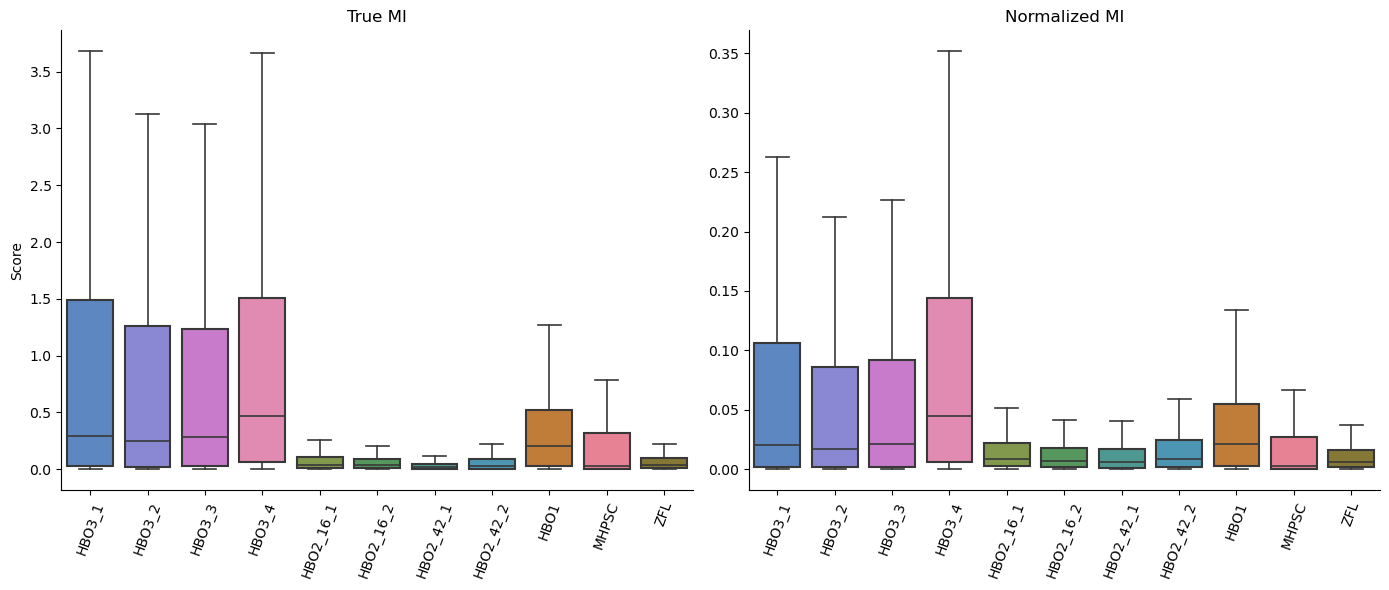

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- Color map ---
color_map = {
    "MHPSC": "#f77189",
    "HBO1": "#d67c23",
    "ZFL": "#928029",
    "HBO2_16_1": "#87a441",
    "HBO2_16_2": "#4ba255",
    "HBO2_42_1": "#40a69b",
    "HBO2_42_2": "#3c9dc4",
    "HBO3_1": "#4b85d2",
    "HBO3_2": "#7f7ae0",
    "HBO3_3": "#d46cd9",
    "HBO3_4": "#f17cb0"
}

# --- Dataset order for x-axis ---
dataset_order = [
    "HBO3_1", "HBO3_2", "HBO3_3", "HBO3_4",
    "HBO2_16_1", "HBO2_16_2", "HBO2_42_1", "HBO2_42_2",
    "HBO1", "MHPSC", "ZFL"
]

# --- Plot ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))  # <-- No `sharey=True`!

score_types = ['true_mi', 'normalized_MI_label_entropy']  
titles = ['True MI', 'Normalized MI']

for ax, score_type, title in zip(axes, score_types, titles):
    sns.boxplot(
        x='dataset',
        y='score',
        data=df_long[df_long['score_type'] == score_type],
        showfliers=False,
        ax=ax,
        zorder=2,
        palette=color_map,
        order=dataset_order,
        boxprops=dict(zorder=2, linewidth=1.5),
        medianprops=dict(linewidth=1.2, zorder=3),
        whiskerprops=dict(linewidth=1.2, zorder=3),
        capprops=dict(linewidth=1.2, zorder=3)
    )
    ax.set_title(title)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=70)
    sns.despine(ax=ax)

# Set ylabel only on the first plot
axes[0].set_ylabel('Score')
axes[1].set_ylabel('')

plt.tight_layout()
plt.savefig(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/all_datasets_MI_vs_NMI_subplots_custom_order_scales.pdf",
    dpi=300,
    bbox_inches='tight'
)
plt.show()


# Distribution of lineages

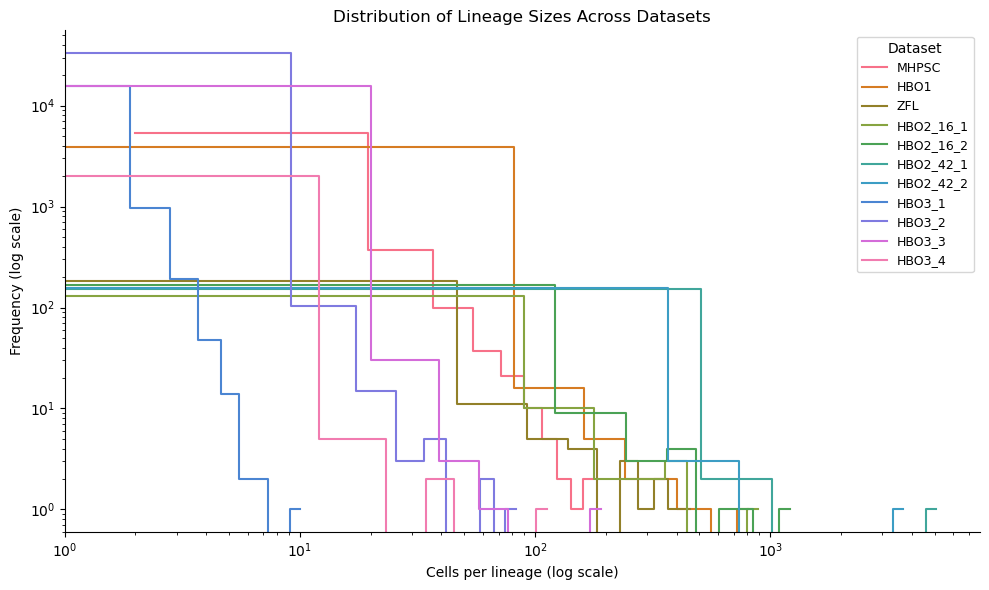

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import numpy as np

file_dict = {
    "weinreb": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/weinreb_all_genes.pkl",
    "treutlein": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/treutlein_all_genes.pkl",
    "junker": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/junker_z5_all_genes.pkl",

    "knoblich_day16_1": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day16_1.pkl",
    "knoblich_day16_2": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day16_2.pkl",
    "knoblich_day42_1": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day42_1.pkl",
    "knoblich_day42_2": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day42_2.pkl",

    "you1": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage1_barcode_all_genes.pkl",
    "you2": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage2_barcode_all_genes.pkl",
    "you3": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage3_barcode_all_genes.pkl",
    "you4": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage4_barcode_all_genes.pkl"
}


custom_titles = {
    "knoblich_day16_1": "HBO2_16_1",
    "knoblich_day16_2": "HBO2_16_2",
    "knoblich_day42_1": "HBO2_42_1",
    "knoblich_day42_2": "HBO2_42_2",
    "weinreb": "MHPSC",
    "treutlein": "HBO1",
    "junker": "ZFL",
    "you1": "HBO3_1",
    "you2": "HBO3_2",
    "you3": "HBO3_3",
    "you4": "HBO3_4"
}

color_map = {
    "weinreb": "#f77189",
    "treutlein": "#d67c23",
    "junker": "#928029",
    "knoblich_day16_1": "#87a441",
    "knoblich_day16_2": "#4ba255",
    "knoblich_day42_1": "#40a69b",
    "knoblich_day42_2": "#3c9dc4",
    "you1": "#4b85d2",
    "you2": "#7f7ae0",
    "you3": "#d46cd9",
    "you4": "#f17cb0"
}

plt.figure(figsize=(10, 6))

for name, path in file_dict.items():
    with open(path, "rb") as f:
        df = pickle.load(f)
    lineage_sizes = df["barcode_cont"].value_counts()

    sns.histplot(
        lineage_sizes,
        bins=10,
        kde=False,
        stat="count",
        element="step",
        fill=False,
        cumulative=False,
        alpha=1,
        label=custom_titles.get(name, name),
        color=color_map.get(name, "gray")
    )

    
sns.despine()
plt.xscale("log")
plt.yscale("log")
plt.xlim(1)
plt.xlabel("Cells per lineage (log scale)")
plt.ylabel("Frequency (log scale)")
plt.legend(title="Dataset", fontsize=9)
plt.title("Distribution of Lineage Sizes Across Datasets")
plt.tight_layout()
plt.savefig("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/overlayed_histogram_loglog.pdf", bbox_inches="tight")
plt.show()


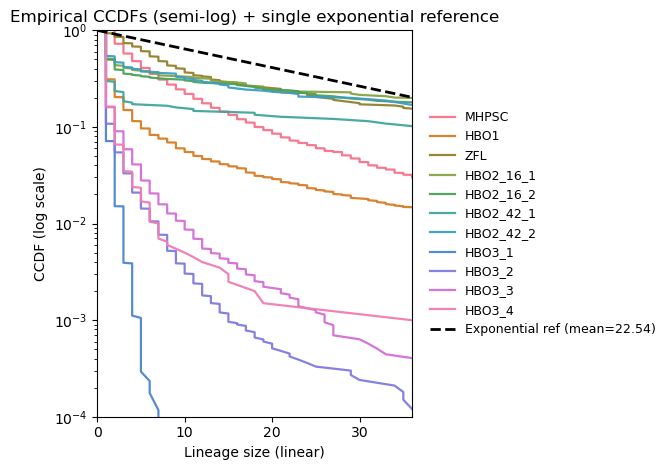

In [6]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

# --- Color map (yours) ---
color_map = {
    "MHPSC": "#f77189",
    "HBO1": "#d67c23",
    "ZFL": "#928029",
    "HBO2_16_1": "#87a441",
    "HBO2_16_2": "#4ba255",
    "HBO2_42_1": "#40a69b",
    "HBO2_42_2": "#3c9dc4",
    "HBO3_1": "#4b85d2",
    "HBO3_2": "#7f7ae0",
    "HBO3_3": "#d46cd9",
    "HBO3_4": "#f17cb0"
}

# --- helpers ---
def empirical_ccdf(samples):
    x = np.sort(np.asarray(samples, float))
    n = x.size
    ccdf = 1.0 - np.arange(1, n + 1) / n
    return x, ccdf

# --- settings ---
LAMBDA_REF = 1.0 / 22.54      # exponential with mean = 22.54
XR_PERC = 99.5                # show up to this percentile across datasets
YMIN = 1e-4                   # lower y-limit in semi-log
OUTPATH = "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/ccdf_semilog_exp_example_tight.pdf"

# --- collect data & decide x-range ---
pooled = []
per_ds = []   # list of (title, x_sorted, ccdf)
for name, path in file_dict.items():
    with open(path, "rb") as f:
        df = pickle.load(f)
    sizes = df["barcode_cont"].value_counts().values.astype(float)
    pooled.append(sizes)
    xs, cc = empirical_ccdf(sizes)
    title = custom_titles.get(name, name)
    per_ds.append((title, xs, cc))
pooled = np.concatenate(pooled)
xmax_plot = float(np.quantile(pooled, XR_PERC/100.0))

# --- plot ---
plt.figure(figsize=(6.6, 4.8))
for title, xs, cc in per_ds:
    c = color_map.get(title, None)
    plt.semilogy(xs, cc, '-', lw=1.6, alpha=0.95,
                 label=title, color=c)

# exponential reference CCDF
xg = np.linspace(0, xmax_plot, 500)
yg = np.exp(-LAMBDA_REF * xg)
plt.semilogy(xg, yg, 'k--', lw=2.0, label="Exponential ref (mean=22.54)")

plt.xlabel("Lineage size (linear)")
plt.ylabel("CCDF (log scale)")
plt.title("Empirical CCDFs (semi-log) + single exponential reference")
plt.xlim(0, xmax_plot)   # just limit the view, not the data
plt.ylim(YMIN, 1)
plt.legend(
    ncol=1, fontsize=9,
    loc="center left", bbox_to_anchor=(1.02, 0.5),  # outside on the right
    frameon=False
)
plt.tight_layout()
plt.savefig(OUTPATH, bbox_inches="tight")
plt.show()



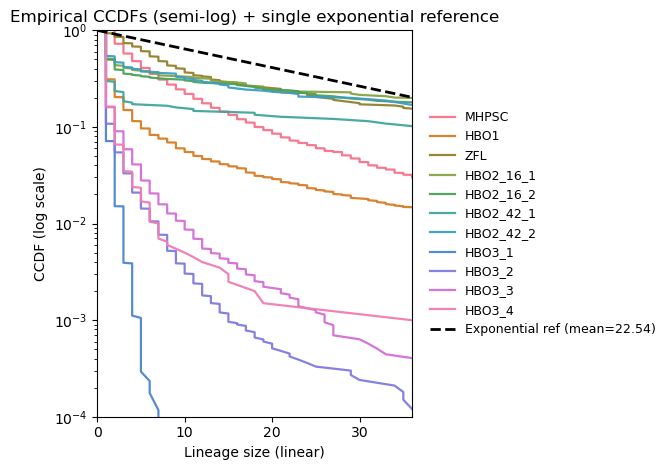

In [7]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

# --- Color map (yours) ---
color_map = {
    "MHPSC": "#f77189",
    "HBO1": "#d67c23",
    "ZFL": "#928029",
    "HBO2_16_1": "#87a441",
    "HBO2_16_2": "#4ba255",
    "HBO2_42_1": "#40a69b",
    "HBO2_42_2": "#3c9dc4",
    "HBO3_1": "#4b85d2",
    "HBO3_2": "#7f7ae0",
    "HBO3_3": "#d46cd9",
    "HBO3_4": "#f17cb0"
}

# --- helpers ---
def empirical_ccdf(samples):
    x = np.sort(np.asarray(samples, float))
    n = x.size
    ccdf = 1.0 - np.arange(1, n + 1) / n
    return x, ccdf

# --- settings ---
LAMBDA_REF = 1.0 / 22.54      # exponential with mean = 22.54
XR_PERC = 99.5                # show up to this percentile across datasets
YMIN = 1e-4                   # lower y-limit in semi-log
OUTPATH = "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/Final_notebooks_for_github/plots/ccdf_semilog_exp_example_tight.pdf"

# --- collect data & decide x-range ---
pooled = []
per_ds = []   # list of (title, x_sorted, ccdf)
for name, path in file_dict.items():
    with open(path, "rb") as f:
        df = pickle.load(f)
    sizes = df["barcode_cont"].value_counts().values.astype(float)
    pooled.append(sizes)
    xs, cc = empirical_ccdf(sizes)
    title = custom_titles.get(name, name)
    per_ds.append((title, xs, cc))
pooled = np.concatenate(pooled)
xmax_plot = float(np.quantile(pooled, XR_PERC/100.0))

# --- plot ---
plt.figure(figsize=(6.6, 4.8))
for title, xs, cc in per_ds:
    c = color_map.get(title, None)
    plt.semilogy(xs, cc, '-', lw=1.6, alpha=0.95,
                 label=title, color=c)

# exponential reference CCDF
xg = np.linspace(0, xmax_plot, 500)
yg = np.exp(-LAMBDA_REF * xg)
plt.semilogy(xg, yg, 'k--', lw=2.0, label="Exponential ref (mean=22.54)")

plt.xlabel("Lineage size (linear)")
plt.ylabel("CCDF (log scale)")
plt.title("Empirical CCDFs (semi-log) + single exponential reference")
plt.xlim(0, xmax_plot)   # just limit the view, not the data
plt.ylim(YMIN, 1)
plt.legend(
    ncol=1, fontsize=9,
    loc="center left", bbox_to_anchor=(1.02, 0.5),  # outside on the right
    frameon=False
)
plt.tight_layout()
plt.savefig(OUTPATH, bbox_inches="tight")
plt.show()



# distribution of lineage size with simulations of log normal 

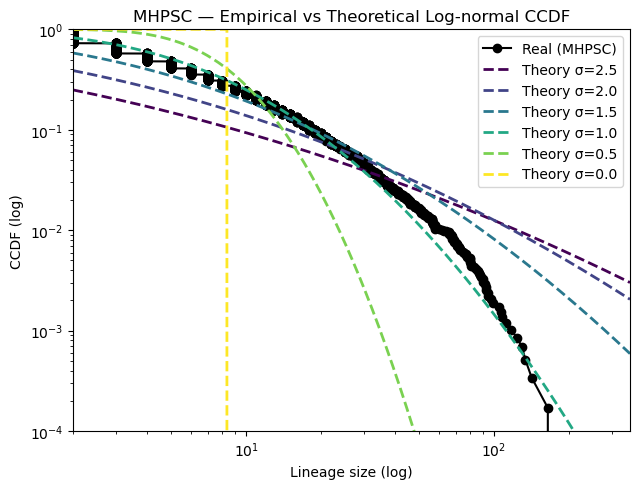

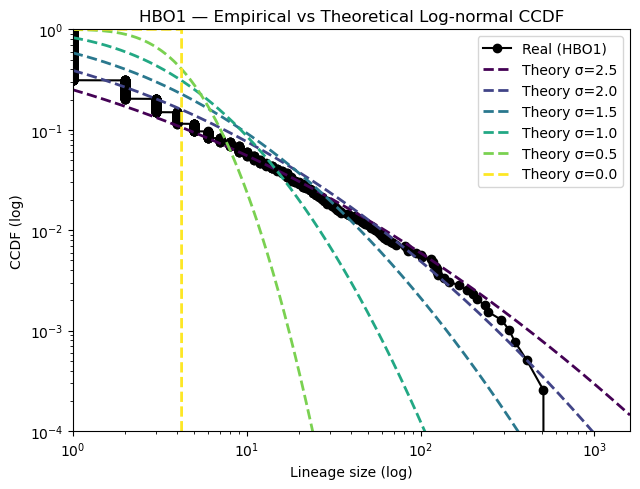

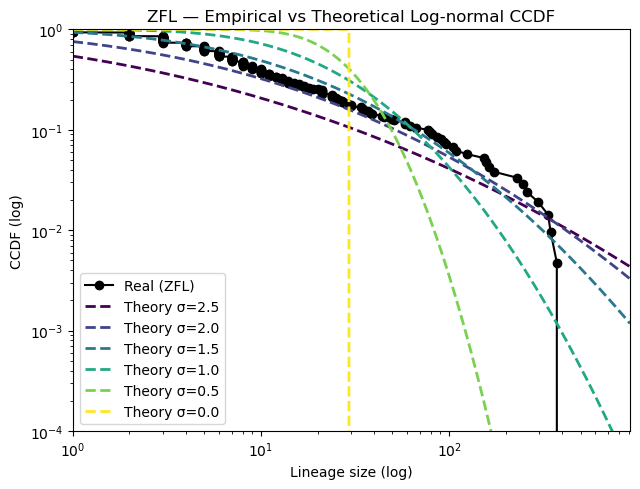

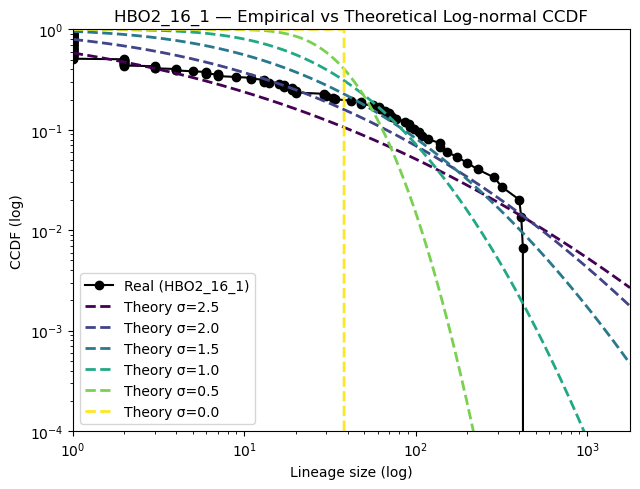

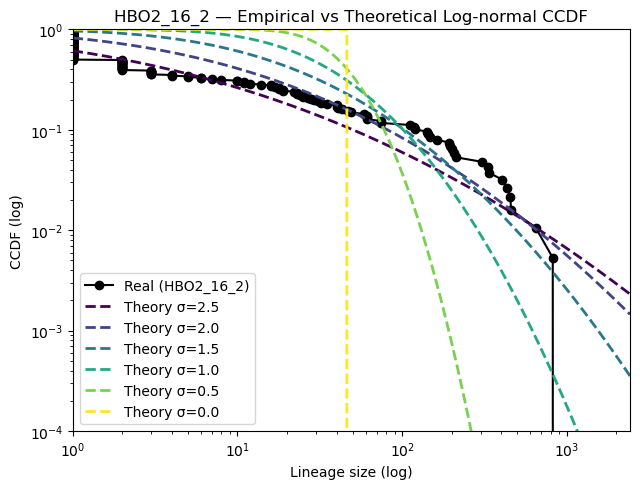

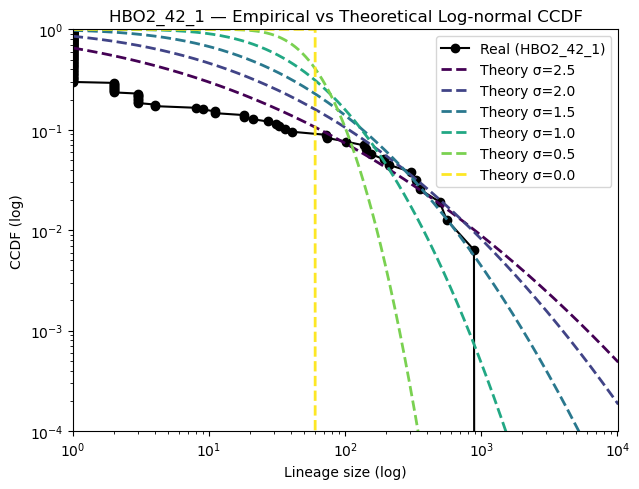

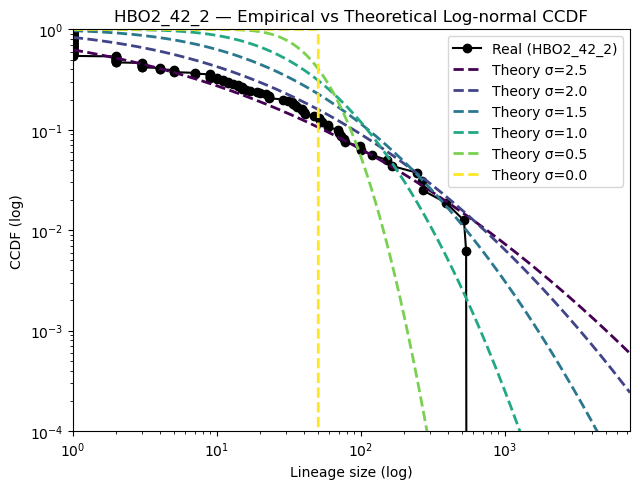

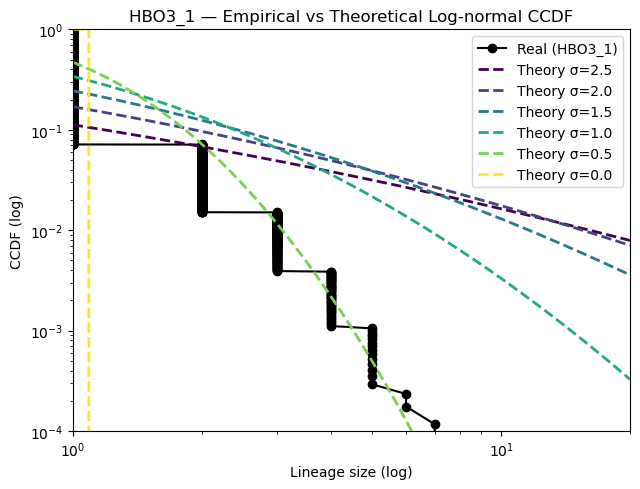

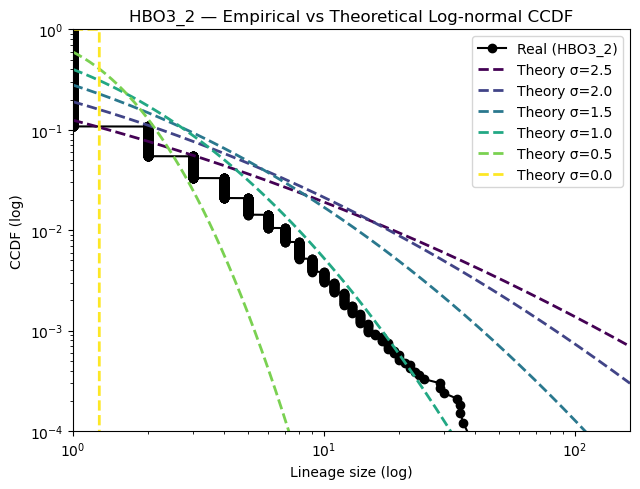

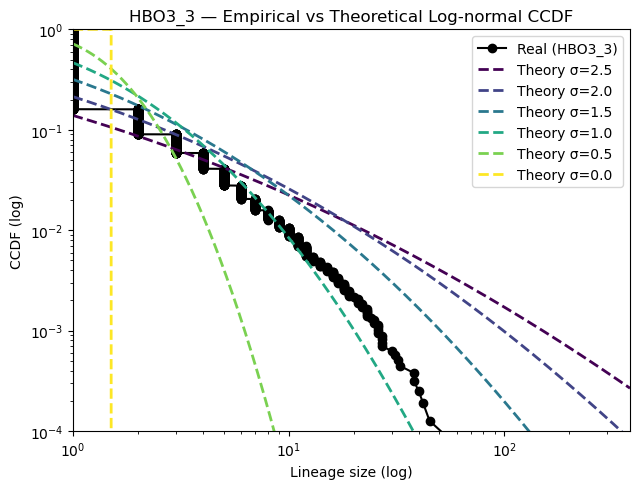

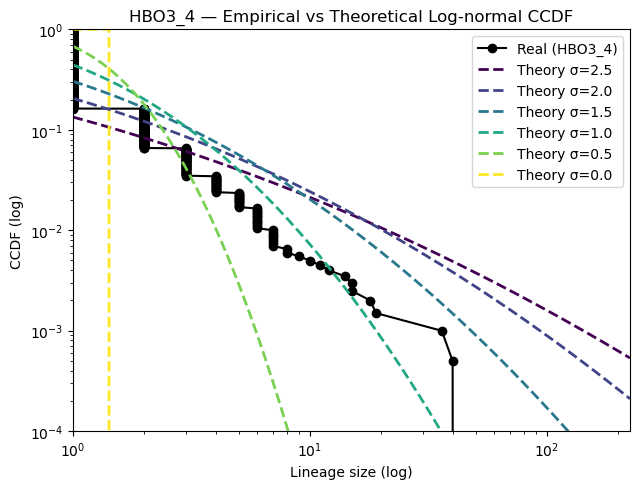

In [8]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import lognorm

# --- Helper: compute empirical CCDF ---
def compute_ccdf(data):
    data = np.sort(data)
    ccdf = 1.0 - np.arange(1, len(data) + 1) / len(data)
    return data, ccdf

# --- CCDF plotting function ---
def plot_ccdf_with_theory(real_sizes, sigma_values, dataset_name="Dataset",
                          tail_factor=2.0, savepath=None):
    plt.figure(figsize=(6.5, 5))

    # Empirical CCDF
    x_real, y_real = compute_ccdf(real_sizes)
    plt.loglog(x_real, y_real, marker='o', linestyle='-', 
               label=f"Real ({dataset_name})", color='black')

    # Stats for mean-matching
    N_total = real_sizes.sum()
    n_lineages = len(real_sizes)
    mean_size = N_total / n_lineages

    # Limit theory x-grid to relevant range
    x_min = max(1, x_real.min())
    x_max = x_real.max() * tail_factor
    x_grid = np.logspace(np.log10(x_min), np.log10(x_max), 800)

    # Theoretical curves
    colors = plt.cm.viridis(np.linspace(0, 1, len(sigma_values)))
    for sigma, color in zip(sigma_values, colors):
        s = max(sigma, 1e-9)
        mu = np.log(mean_size) - 0.5 * s**2
        ccdf = 1.0 - lognorm.cdf(x_grid, s=s, scale=np.exp(mu))
        plt.loglog(x_grid, ccdf, linestyle='--', linewidth=2, 
                   color=color, label=f"Theory σ={sigma:.1f}")

    plt.xlabel("Lineage size (log)")
    plt.ylabel("CCDF (log)")
    plt.title(f"{dataset_name} — Empirical vs Theoretical Log-normal CCDF")
    plt.legend()

    # Axis limits
    plt.xlim(x_min, x_max)
    plt.ylim(1e-4, 1.0)

    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, bbox_inches="tight")
    plt.show()

# --- Apply to all datasets ---
sigma_values = [2.5, 2.0, 1.5, 1.0, 0.5, 0.0]
tail_factor = 2.0  # plot up to 2x the largest observed lineage size

for name, path in file_dict.items():
    with open(path, "rb") as f:
        df = pickle.load(f)
    
    real_sizes = df["barcode_cont"].value_counts().values

    plot_ccdf_with_theory(
        real_sizes,
        sigma_values,
        dataset_name=custom_titles.get(name, name),
        tail_factor=tail_factor,
        savepath=None  # or set to a filename if you want to save
    )


# simulation

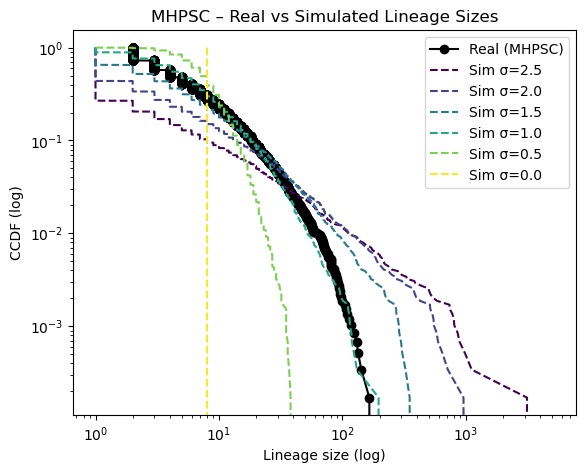

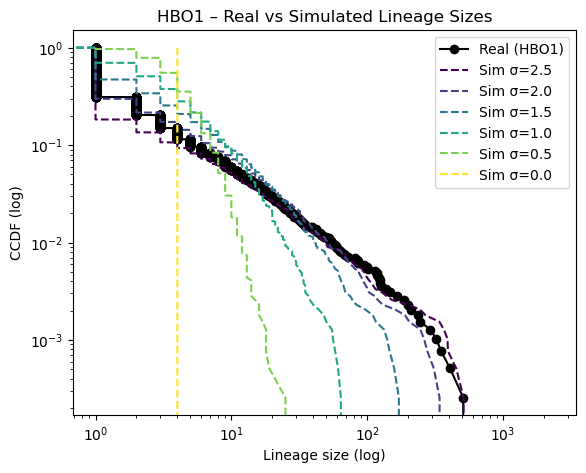

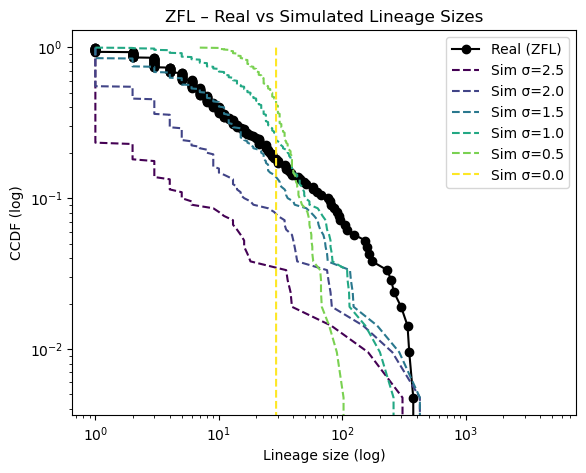

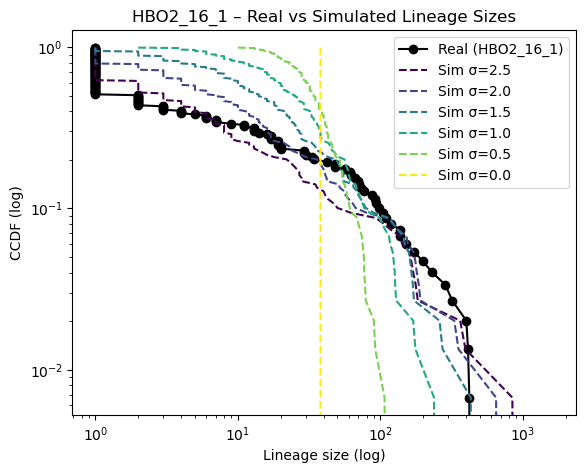

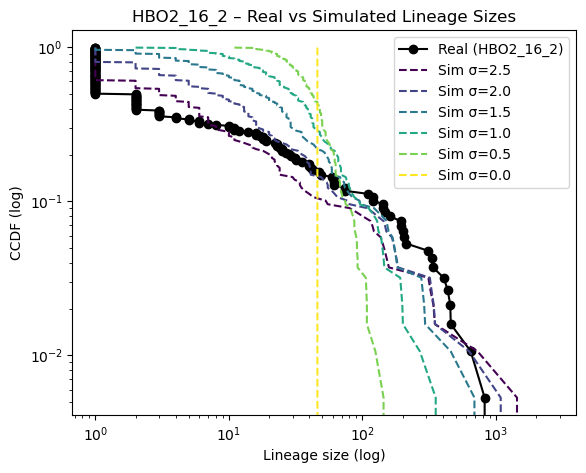

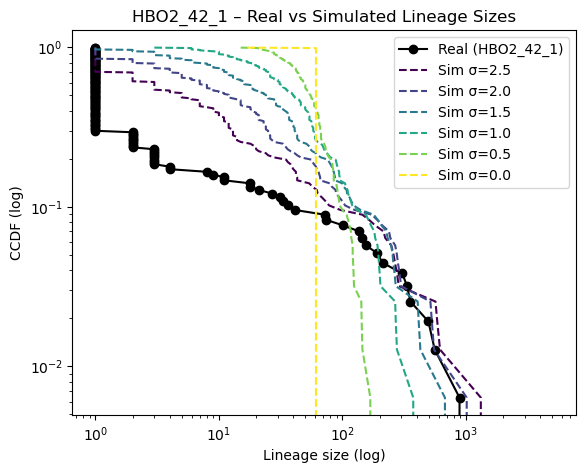

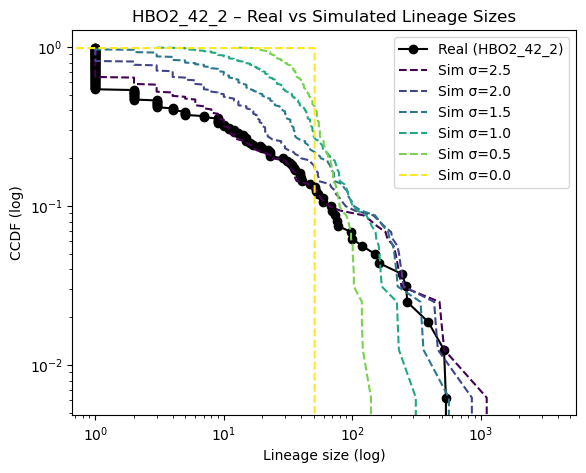

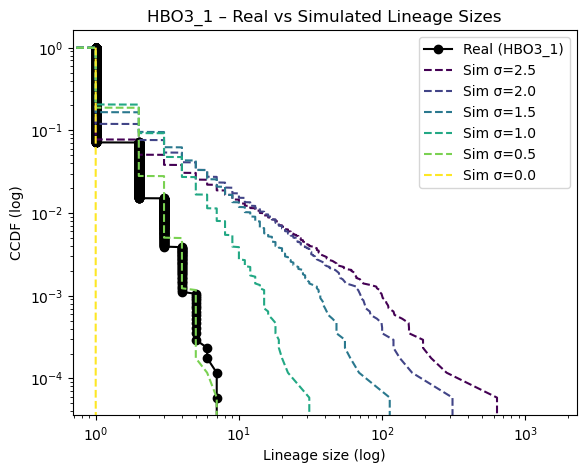

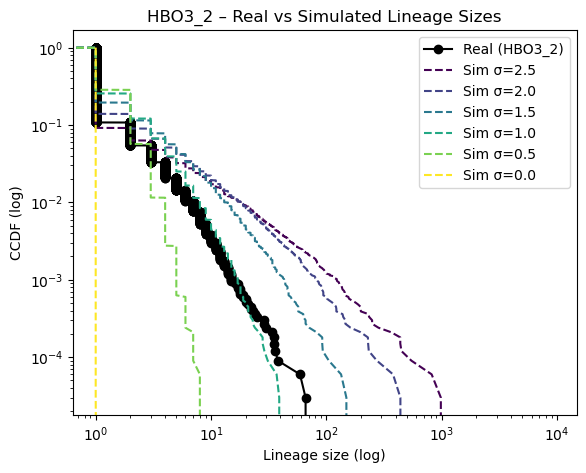

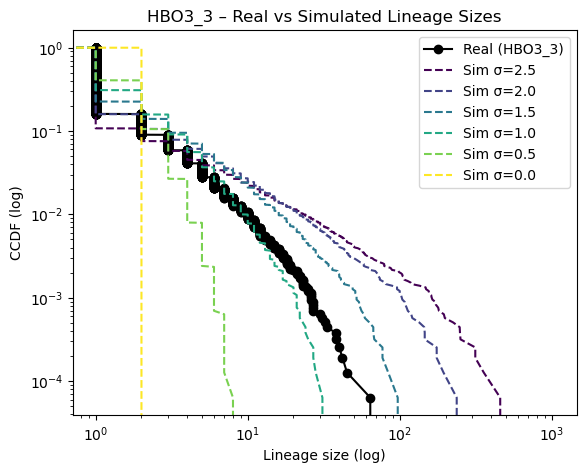

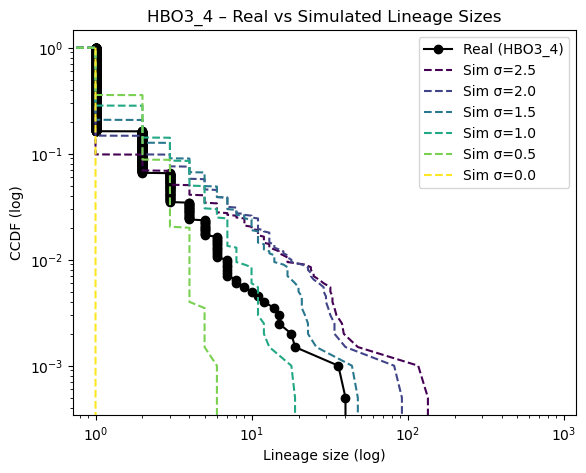

In [9]:
import pickle
import numpy as np
import matplotlib.pyplot as plt

# --- Helper functions ---
def compute_ccdf(data):
    data = np.sort(data)
    ccdf = 1.0 - np.arange(1, len(data) + 1) / len(data)
    return data, ccdf

def simulate_lineages_log_normal(N_total, n_lineages, sigma=1.5, seed=0):
    np.random.seed(seed)
    mu = np.log(N_total / n_lineages) - sigma**2 / 2
    raw = np.random.lognormal(mean=mu, sigma=sigma, size=n_lineages)

    normalized = raw / raw.sum() * N_total
    sizes = np.round(normalized).astype(int)

    # Ensure minimum size = 1
    sizes[sizes < 1] = 1

    # Adjust total to match N_total exactly
    delta = N_total - sizes.sum()
    sizes[np.argmax(sizes)] += delta

    return sizes

def plot_ccdf_comparison(real_sizes, sim_sizes_list, sigma_values, dataset_name="Dataset"):
    plt.figure(figsize=(6.5, 5))

    # Empirical CCDF
    x_real, y_real = compute_ccdf(real_sizes)
    plt.loglog(x_real, y_real, marker='o', linestyle='-', label=f"Real ({dataset_name})", color='black')

    # Simulated CCDFs
    colors = plt.cm.viridis(np.linspace(0, 1, len(sim_sizes_list)))
    for sim_sizes, sigma, color in zip(sim_sizes_list, sigma_values, colors):
        x_sim, y_sim = compute_ccdf(sim_sizes)
        plt.loglog(x_sim, y_sim, linestyle='--', label=f"Sim σ={sigma:.1f}", color=color)

    plt.xlabel("Lineage size (log)")
    plt.ylabel("CCDF (log)")
    plt.title(f"{dataset_name} – Real vs Simulated Lineage Sizes")
    plt.legend()
    plt.savefig(f"/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/ccdf_comparison_{dataset_name}.pdf", bbox_inches="tight")
    plt.show()

# --- Define sigmas to simulate ---
sigma_values = [2.5, 2.0, 1.5, 1.0, 0.5, 0.0]

# --- Loop through datasets ---
for name, path in file_dict.items():
    with open(path, "rb") as f:
        df = pickle.load(f)

    real_sizes = df["barcode_cont"].value_counts().values
    N_total = real_sizes.sum()
    n_lineages = len(real_sizes)

    sim_sizes_list = [
        simulate_lineages_log_normal(N_total, n_lineages, sigma=sigma, seed=42)
        for sigma in sigma_values
    ]

    plot_ccdf_comparison(real_sizes, sim_sizes_list, sigma_values, dataset_name=custom_titles.get(name, name))


# fit of log-normal 

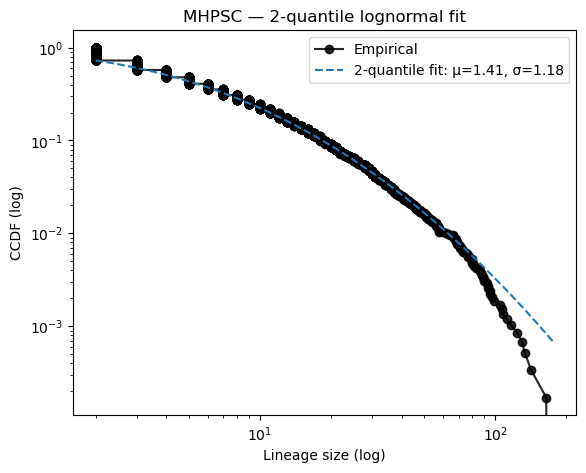

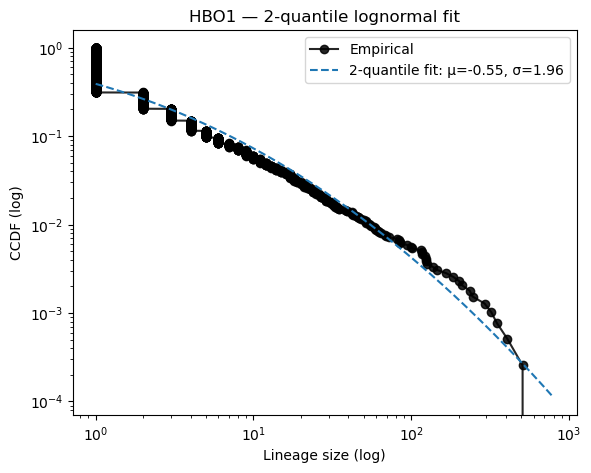

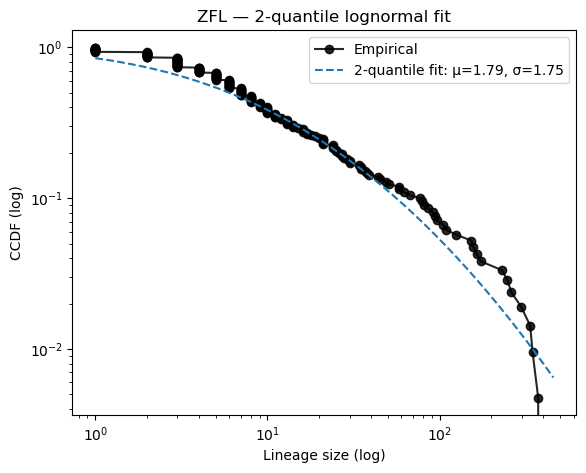

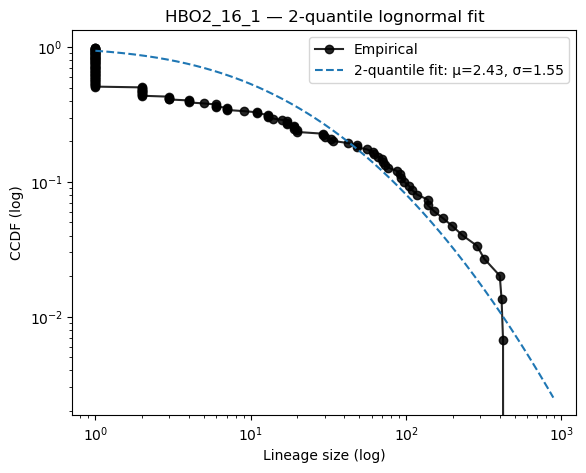

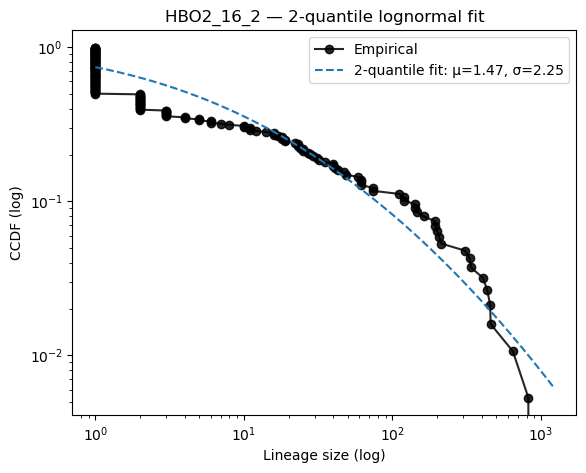

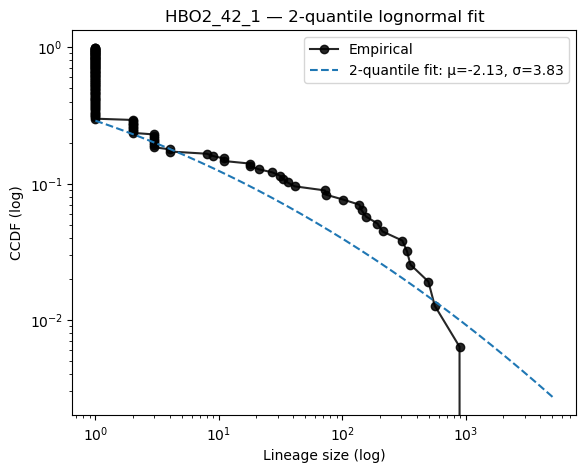

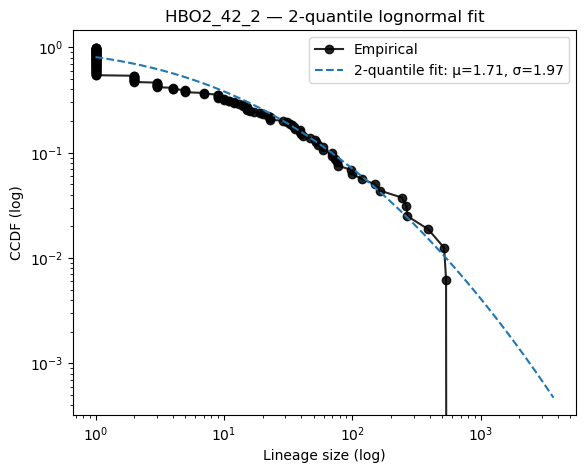

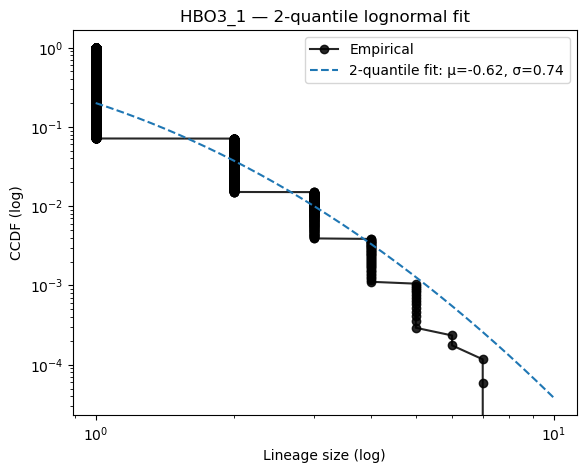

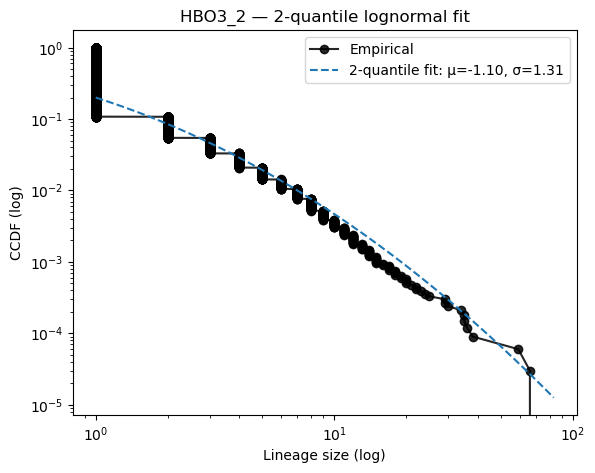

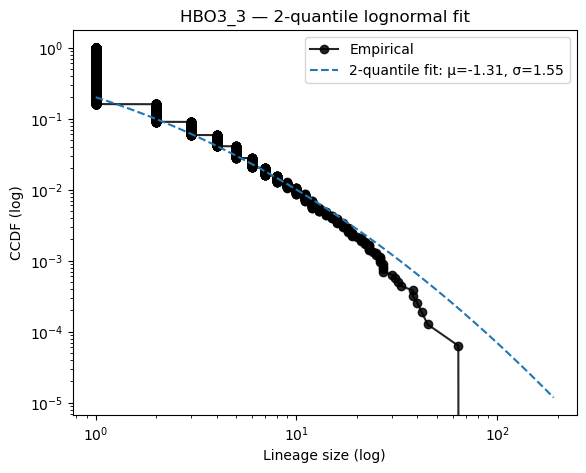

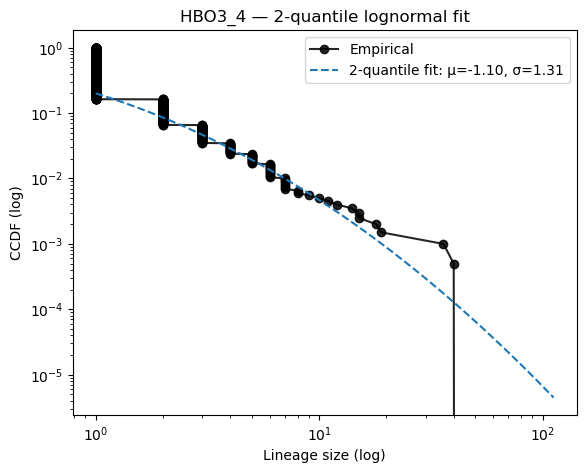

MHPSC            μ=1.409  σ=1.175  (2-quantile: p1=0.8, p2=0.99)
HBO1             μ=-0.550  σ=1.959  (2-quantile: p1=0.8, p2=0.99)
ZFL              μ=1.789  σ=1.745  (2-quantile: p1=0.8, p2=0.99)
HBO2_16_1        μ=2.431  σ=1.552  (2-quantile: p1=0.8, p2=0.99)
HBO2_16_2        μ=1.471  σ=2.253  (2-quantile: p1=0.8, p2=0.99)
HBO2_42_1        μ=-2.126  σ=3.831  (2-quantile: p1=0.8, p2=0.99)
HBO2_42_2        μ=1.713  σ=1.966  (2-quantile: p1=0.8, p2=0.99)
HBO3_1           μ=-0.623  σ=0.740  (2-quantile: p1=0.8, p2=0.99)
HBO3_2           μ=-1.103  σ=1.311  (2-quantile: p1=0.8, p2=0.99)
HBO3_3           μ=-1.305  σ=1.551  (2-quantile: p1=0.8, p2=0.99)
HBO3_4           μ=-1.103  σ=1.311  (2-quantile: p1=0.8, p2=0.99)


In [10]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# ---------- helper: empirical "higher" quantile ----------
def q_higher(x, p):
    """Smallest order statistic >= p (works well for integer data)."""
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    if x.size == 0:
        raise ValueError("Empty data.")
    x.sort()
    idx = int(np.ceil(p * x.size)) - 1
    idx = min(max(idx, 0), x.size - 1)
    return x[idx]

# ---------- 2-quantile lognormal fit ----------
def fit_lognormal_two_quantiles(sizes, p1=0.70, p2=0.95, min_size=1):
    x = np.asarray(sizes, float)
    x = x[x >= min_size]
    if x.size < 5:
        raise ValueError("Too few points ≥ min_size.")
    q1, q2 = q_higher(x, p1), q_higher(x, p2)
    z1, z2 = norm.ppf(p1), norm.ppf(p2)
    if q1 <= 0 or q2 <= 0 or q2 == q1:
        raise ValueError("Quantiles degenerate; adjust p1/p2 or min_size.")
    sigma = (np.log(q2) - np.log(q1)) / (z2 - z1)
    mu = np.log(q1) - sigma * z1
    return float(mu), float(abs(sigma))

# ---------- CCDF plotting ----------
def empirical_ccdf(x_all):
    xs = np.sort(np.asarray(x_all, float))
    ccdf = 1.0 - np.arange(1, len(xs)+1) / len(xs)
    return xs, ccdf

def lognormal_ccdf(x, mu, sigma):
    z = (np.log(x) - mu) / sigma
    return 1.0 - norm.cdf(z)

def plot_ccdf_with_fit(sizes_all, mu, sigma, dataset_name, outpath=None):
    xs, ccdf = empirical_ccdf(sizes_all)
    plt.figure(figsize=(6.5, 5))
    plt.loglog(xs, ccdf, 'ko-', alpha=0.85, label="Empirical")
    xg = np.logspace(np.log10(max(1, xs.min())), np.log10(xs.max()), 500)
    plt.loglog(xg, lognormal_ccdf(xg, mu, sigma), '--',
               label=f"2-quantile fit: μ={mu:.2f}, σ={sigma:.2f}")
    plt.xlabel("Lineage size (log)")
    plt.ylabel("CCDF (log)")
    plt.title(f"{dataset_name} — 2-quantile lognormal fit")
    plt.legend()
    if outpath:
        plt.savefig(outpath, bbox_inches="tight")
    plt.show()

# ---------- run over datasets ----------
MIN_SIZE = 1
P1, P2 = 0.80, 0.99  # quantiles used for the fit

fit_results = {}
for name, path in file_dict.items():
    with open(path, "rb") as f:
        df = pickle.load(f)

    sizes = df["barcode_cont"].value_counts().values
    title = custom_titles.get(name, name)

    mu, sigma = fit_lognormal_two_quantiles(sizes, p1=P1, p2=P2, min_size=MIN_SIZE)
    fit_results[name] = dict(mu=mu, sigma=sigma, title=title)

    outpdf = f"/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/ccdf_2qfit_{title}.pdf"
    plot_ccdf_with_fit(sizes, mu, sigma, title, outpath=outpdf)

# summary
for k, v in fit_results.items():
    print(f"{v['title']:<16} μ={v['mu']:.3f}  σ={v['sigma']:.3f}  (2-quantile: p1={P1}, p2={P2})")


# for supplement in 2 files

In [11]:
import math
import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# ---------- helper: empirical "higher" quantile ----------
def q_higher(x, p):
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    if x.size == 0:
        raise ValueError("Empty data.")
    x.sort()
    idx = int(np.ceil(p * x.size)) - 1
    idx = min(max(idx, 0), x.size - 1)
    return x[idx]

# ---------- 2-quantile lognormal fit ----------
def fit_lognormal_two_quantiles(sizes, p1=0.70, p2=0.95, min_size=1):
    x = np.asarray(sizes, float)
    x = x[x >= min_size]
    if x.size < 5:
        raise ValueError("Too few points ≥ min_size.")
    q1, q2 = q_higher(x, p1), q_higher(x, p2)
    z1, z2 = norm.ppf(p1), norm.ppf(p2)
    if q1 <= 0 or q2 <= 0 or q2 == q1:
        raise ValueError("Quantiles degenerate; adjust p1/p2 or min_size.")
    sigma = (np.log(q2) - np.log(q1)) / (z2 - z1)
    mu = np.log(q1) - sigma * z1
    return float(mu), float(abs(sigma))

# ---------- CCDF helpers ----------
def empirical_ccdf(x_all):
    xs = np.sort(np.asarray(x_all, float))
    ccdf = 1.0 - np.arange(1, len(xs)+1) / len(xs)
    return xs, ccdf

def lognormal_ccdf(x, mu, sigma):
    z = (np.log(x) - mu) / sigma
    return 1.0 - norm.cdf(z)

def _plot_ccdf_on_axis(ax, sizes, mu, sigma, title, legend_font=7):
    xs, ccdf = empirical_ccdf(sizes)
    ax.loglog(xs, ccdf, 'o-', markersize=2.5, linewidth=1.0, alpha=0.9, label="Empirical", color="black")
    xg = np.logspace(np.log10(max(1, xs.min())), np.log10(xs.max()), 400)
    ax.loglog(xg, lognormal_ccdf(xg, mu, sigma), '--', linewidth=1.2,
              label=f"fit: μ={mu:.2f}, σ={sigma:.2f}")
    ax.set_title(title, fontsize=9, pad=3)
    ax.grid(False)
    # small legend inside; adjust if it overlaps
    leg = ax.legend(frameon=False, fontsize=legend_font, loc="upper right", handlelength=2.5, borderaxespad=0.2)
    for line in leg.get_lines():
        line.set_linewidth(1.2)

# ---------- build fit results first (same as yours) ----------
MIN_SIZE = 1
P1, P2 = 0.80, 0.99  # quantiles used for the fit

# If you have a preferred display order, set it here via titles you use elsewhere.
preferred_order_titles = [
    "MHPSC", "HBO1", "ZFL",
    "HBO2_16_1", "HBO2_16_2", "HBO2_42_1", "HBO2_42_2",
    "HBO3_1", "HBO3_2", "HBO3_3", "HBO3_4"
]

fit_results = {}   # name -> dict(mu, sigma, title, sizes)
for name, path in file_dict.items():
    with open(path, "rb") as f:
        df = pickle.load(f)
    sizes = df["barcode_cont"].value_counts().values
    title = custom_titles.get(name, name)
    mu, sigma = fit_lognormal_two_quantiles(sizes, p1=P1, p2=P2, min_size=MIN_SIZE)
    fit_results[name] = dict(mu=mu, sigma=sigma, title=title, sizes=sizes)

# Sort datasets by preferred title order, then any remainder alphabetically
present_titles = {v["title"]: k for k, v in fit_results.items()}
ordered_titles = [t for t in preferred_order_titles if t in present_titles]
# add any missing (unexpected) titles
other_titles = sorted([v["title"] for v in fit_results.values() if v["title"] not in ordered_titles])
ordered_titles += other_titles

ordered_names = [present_titles[t] for t in ordered_titles]

# ---------- grid export helper ----------
def export_ccdf_grid(names_subset, pdf_path, ncols=3, lock_axes=False, suptitle=None):
    n = len(names_subset)
    nrows = math.ceil(n / ncols)

    # Compute common axes if requested
    xmins, xmaxs, ymins, ymaxs = [], [], [], []
    if lock_axes:
        for nm in names_subset:
            xs, ccdf = empirical_ccdf(fit_results[nm]["sizes"])
            xmins.append(xs.min())
            xmaxs.append(xs.max())
            ymins.append((ccdf[ccdf>0]).min())
            ymaxs.append(ccdf.max())
        x_min = max(1.0, np.min(xmins))
        x_max = np.max(xmaxs)
        y_min = max(1e-4, np.min(ymins))
        y_max = 1.0

    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*3.0, nrows*2.8))
    axes = np.atleast_2d(axes).ravel()

    for i, nm in enumerate(names_subset):
        ax = axes[i]
        d = fit_results[nm]
        _plot_ccdf_on_axis(ax, d["sizes"], d["mu"], d["sigma"], d["title"])
        if lock_axes:
            ax.set_xlim([x_min, x_max])
            ax.set_ylim([y_min, y_max])
        if i // ncols == nrows - 1:  # bottom row
            ax.set_xlabel("Lineage size (log)", fontsize=8)
        else:
            ax.set_xlabel("")
        if i % ncols == 0:           # first column
            ax.set_ylabel("CCDF (log)", fontsize=8)
        else:
            ax.set_ylabel("")
        ax.tick_params(labelsize=7, length=3)

    # Hide any unused axes
    for j in range(i+1, len(axes)):
        axes[j].axis("off")

    if suptitle:
        fig.suptitle(suptitle, fontsize=11, y=0.99)

    plt.tight_layout(rect=[0, 0, 1, 0.98] if suptitle else [0, 0, 1, 1])
    plt.savefig(pdf_path, bbox_inches="tight")
    plt.close(fig)

# ---------- choose 6 for the first PDF and 5 for the second ----------
six = ordered_names[:6]
five = ordered_names[6:11]  # assuming 11 datasets total

outdir = "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/"
pdf1 = f"{outdir}/ccdf_2qfit_grid_6panels.pdf"
pdf2 = f"{outdir}/ccdf_2qfit_grid_5panels.pdf"

# Set lock_axes=True if you want identical axes across panels within each PDF
export_ccdf_grid(six,  pdf1, ncols=3, lock_axes=False, suptitle="CCDF + 2-quantile log-normal fit")
export_ccdf_grid(five, pdf2, ncols=3, lock_axes=False, suptitle="CCDF + 2-quantile log-normal fit")

# ---------- optional: quick text summary in console ----------
for k in ordered_names:
    v = fit_results[k]
    print(f"{v['title']:<12}  μ={v['mu']:.3f}  σ={v['sigma']:.3f}  (p1={P1}, p2={P2}, n={len(v['sizes'])})")

print(f"\nWrote:\n  {pdf1}\n  {pdf2}")


MHPSC         μ=1.409  σ=1.175  (p1=0.8, p2=0.99, n=5864)
HBO1          μ=-0.550  σ=1.959  (p1=0.8, p2=0.99, n=3905)
ZFL           μ=1.789  σ=1.745  (p1=0.8, p2=0.99, n=210)
HBO2_16_1     μ=2.431  σ=1.552  (p1=0.8, p2=0.99, n=149)
HBO2_16_2     μ=1.471  σ=2.253  (p1=0.8, p2=0.99, n=188)
HBO2_42_1     μ=-2.126  σ=3.831  (p1=0.8, p2=0.99, n=157)
HBO2_42_2     μ=1.713  σ=1.966  (p1=0.8, p2=0.99, n=160)
HBO3_1        μ=-0.623  σ=0.740  (p1=0.8, p2=0.99, n=17075)
HBO3_2        μ=-1.103  σ=1.311  (p1=0.8, p2=0.99, n=33308)
HBO3_3        μ=-1.305  σ=1.551  (p1=0.8, p2=0.99, n=15792)
HBO3_4        μ=-1.103  σ=1.311  (p1=0.8, p2=0.99, n=2004)

Wrote:
  /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures//ccdf_2qfit_grid_6panels.pdf
  /fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures//ccdf_2qfit_grid_5panels.pdf


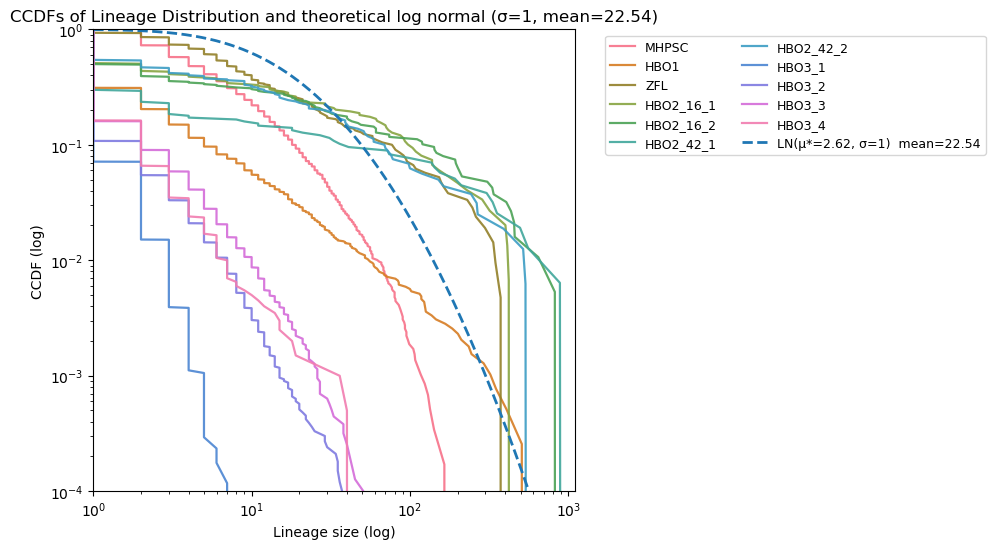

In [12]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm


color_map = {
    "weinreb": "#f77189",
    "treutlein": "#d67c23",
    "junker": "#928029",
    "knoblich_day16_1": "#87a441",
    "knoblich_day16_2": "#4ba255",
    "knoblich_day42_1": "#40a69b",
    "knoblich_day42_2": "#3c9dc4",
    "you1": "#4b85d2",
    "you2": "#7f7ae0",
    "you3": "#d46cd9",
    "you4": "#f17cb0"
}

# --- helpers ---
def empirical_ccdf(x):
    xs = np.sort(np.asarray(x, float))
    ccdf = 1.0 - np.arange(1, len(xs)+1) / len(xs)
    return xs, ccdf

def ln_ccdf_theory(x, mu, sigma=1.0):
    z = (np.log(x) - mu) / sigma
    return 1.0 - norm.cdf(z)

# --- settings ---
M_TARGET = 22.54
MU_STAR  = np.log(M_TARGET) - 0.5     # so that E[Y] = exp(mu+1/2) = 22.54

# --- plot all empirical (original) CCDFs + single theory curve ---
plt.figure(figsize=(10, 5.6))

xmin, xmax = np.inf, -np.inf
for name, path in file_dict.items():
    with open(path, "rb") as f:
        df = pickle.load(f)
    sizes = df["barcode_cont"].value_counts().values.astype(float)

    xs, cc = empirical_ccdf(sizes)
    color = color_map.get(name, "gray")  # fallback to gray if not found
    plt.loglog(xs, cc, '-', lw=1.6, alpha=0.9,
               label=custom_titles.get(name, name),
               color=color)

    xmin = min(xmin, xs.min())
    xmax = max(xmax, xs.max())

# theory curve at sigma=1 with mean=22.54
xg = np.logspace(np.log10(max(1e-3, xmin)), np.log10(xmax), 800)
th = ln_ccdf_theory(xg, MU_STAR, sigma=1.0)
plt.loglog(xg, th, '--', lw=2.0,
           label=f"LN(μ*={MU_STAR:.2f}, σ=1)  mean={M_TARGET:.2f}")

plt.xlabel("Lineage size (log)")
plt.ylabel("CCDF (log)")
plt.title("CCDFs of Lineage Distribution and theoretical log normal (σ=1, mean=22.54)")
plt.ylim(1e-4, 1)
plt.xlim(1, 1100)
plt.legend(
    ncol=2,
    fontsize=9,
    loc="upper left",
    bbox_to_anchor=(1.05, 1)   # anchor outside the axes
)

plt.tight_layout()
plt.savefig(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/ccdf_empirical_plus_sigma1_mean22_54.pdf",
    bbox_inches="tight"
)
plt.show()

Common target mean M_target = 22.135  -> mu_target = 2.597
MHPSC            new mean=23.116  new sigma=0.758
HBO1             new mean=26.715  new sigma=0.462
ZFL              new mean=24.734  new sigma=0.791
HBO2_16_1        new mean=19.304  new sigma=1.250
HBO2_16_2        new mean=21.847  new sigma=0.876
HBO2_42_1        new mean=34.138  new sigma=0.462
HBO2_42_2        new mean=21.599  new sigma=0.936
HBO3_1           new mean=35.867  new sigma=0.290
HBO3_2           new mean=36.366  new sigma=0.291
HBO3_3           new mean=37.926  new sigma=0.321
HBO3_4           new mean=38.672  new sigma=0.331


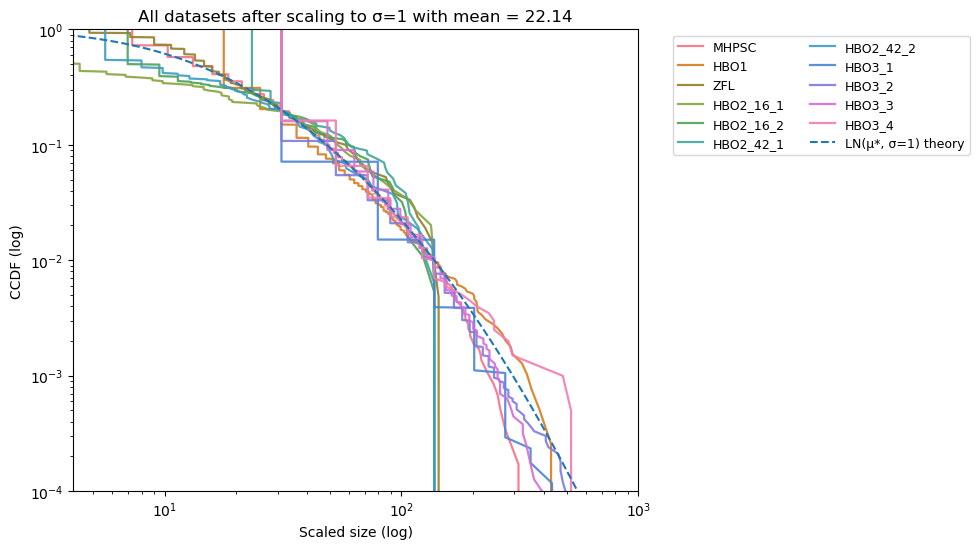

In [13]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# ---------- helper: empirical "higher" quantile ----------
def q_higher(x, p):
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    if x.size == 0: raise ValueError("Empty data.")
    x.sort()
    idx = int(np.ceil(p * x.size)) - 1
    idx = min(max(idx, 0), x.size - 1)
    return x[idx]

# ---------- 2-quantile lognormal fit ----------
def fit_lognormal_two_quantiles(sizes, p1=0.80, p2=0.99, min_size=1):
    x = np.asarray(sizes, float)
    x = x[x >= min_size]
    if x.size < 5: raise ValueError("Too few points ≥ min_size.")
    q1, q2 = q_higher(x, p1), q_higher(x, p2)
    z1, z2 = norm.ppf(p1), norm.ppf(p2)
    sigma = (np.log(q2) - np.log(q1)) / (z2 - z1)
    mu = np.log(q1) - sigma * z1
    return float(mu), float(abs(sigma))

# ---------- sigma=1 rescaling to a COMMON mean M_target ----------
def rescale_sigma1_to_target_mean(x, mu_hat, sigma_hat, M_target):
    """
    Make sigma=1 and set the arithmetic mean to M_target.
    For LN(mu_target, 1): E[Y] = exp(mu_target + 1/2) = M_target
    -> mu_target = ln(M_target) - 1/2
    """
    x = np.asarray(x, float)
    if np.any(x <= 0):
        raise ValueError("All values must be > 0 for log transform.")
    mu_target = np.log(M_target) - 0.5
    return np.exp((np.log(x) - mu_hat) / sigma_hat + mu_target)



# ===================== MAIN =====================
# expects: file_dict, custom_titles already defined in your session

P1, P2 = 0.80, 0.99
MIN_SIZE = 1
M_TARGET = None   # set to a number to force a specific common mean (e.g., 50.0)

fit_results = {}
dataset_means = []

# 1) Fit mu,sigma and collect original means
for name, path in file_dict.items():
    with open(path, "rb") as f:
        df = pickle.load(f)
    sizes = df["barcode_cont"].value_counts().values.astype(float)
    mu, sigma = fit_lognormal_two_quantiles(sizes, p1=P1, p2=P2, min_size=MIN_SIZE)
    fit_results[name] = dict(mu=mu, sigma=sigma, title=custom_titles.get(name, name), sizes=sizes)
    dataset_means.append(np.mean(sizes))

# 2) Choose common target mean
if M_TARGET is None:
    M_target = float(np.mean(dataset_means))   # unweighted average of dataset means
else:
    M_target = float(M_TARGET)
mu_target_common = np.log(M_target) - 0.5

print(f"Common target mean M_target = {M_target:.3f}  -> mu_target = {mu_target_common:.3f}")

# 3) Rescale and check
scaled = {}
for name, info in fit_results.items():
    y = rescale_sigma1_to_target_mean(info["sizes"], info["mu"], info["sigma"], M_target=M_target)
    # quick sanity check
    z = np.log(y)
    print(f"{info['title']:<16} new mean={y.mean():.3f}  new sigma={z.std(ddof=0):.3f}")
    scaled[name] = y

# 4) Plot all scaled CCDFs on one figure
plt.figure(figsize=(10, 5.6))

xmin = min(min(v) for v in scaled.values())
xmax = max(max(v) for v in scaled.values())

for name, y in scaled.items():
    xs, cc = empirical_ccdf(y)
    color = color_map.get(name, "gray")  # fallback to gray if not found
    plt.loglog(xs, cc, '-', lw=1.6, label=fit_results[name]["title"],
               color=color, alpha=0.9)

# Optional: overlay the common theoretical LN curve (mu=mu_target_common, sigma=1)
xg = np.logspace(np.log10(max(1e-6, xmin)), np.log10(xmax), 600)
th = 1.0 - norm.cdf((np.log(xg) - mu_target_common) / 1.0)
plt.loglog(xg, th, '--', lw=1.5, label="LN(μ*, σ=1) theory")

plt.xlabel("Scaled size (log)")
plt.ylabel("CCDF (log)")
plt.title(f"All datasets after scaling to σ=1 with mean = {M_target:.2f}")
plt.legend(ncol=2, fontsize=9, loc="upper left",
    bbox_to_anchor=(1.05, 1)   # anchor outside the axes
)
plt.xlim(4.1, 1e3)
plt.ylim(1e-4, 1)
plt.tight_layout()
plt.savefig(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/ccdf_all_scaled_common_mean.pdf",
    bbox_inches="tight"
)
plt.show()


# intra lineage distribution of counts 

In [14]:
import pandas as pd
import os

BASE = (
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/calc_files/MI/"
    "mi_analysis_results_MI_label_entropy_all_genes_parallel"
)

datasets = [
    "junker",
    "knoblich_day16_1", "knoblich_day16_2",
    "knoblich_day42_1", "knoblich_day42_2",
    "treutlein", "weinreb",
    "you1", "you2", "you3", "you4"
]

normalized_mi_dict = {}

for ds in datasets:
    path = os.path.join(BASE, f"MI_label_entropy_{ds}_50_permutations.csv")
    normalized_mi_dict[ds] = pd.read_csv(path)



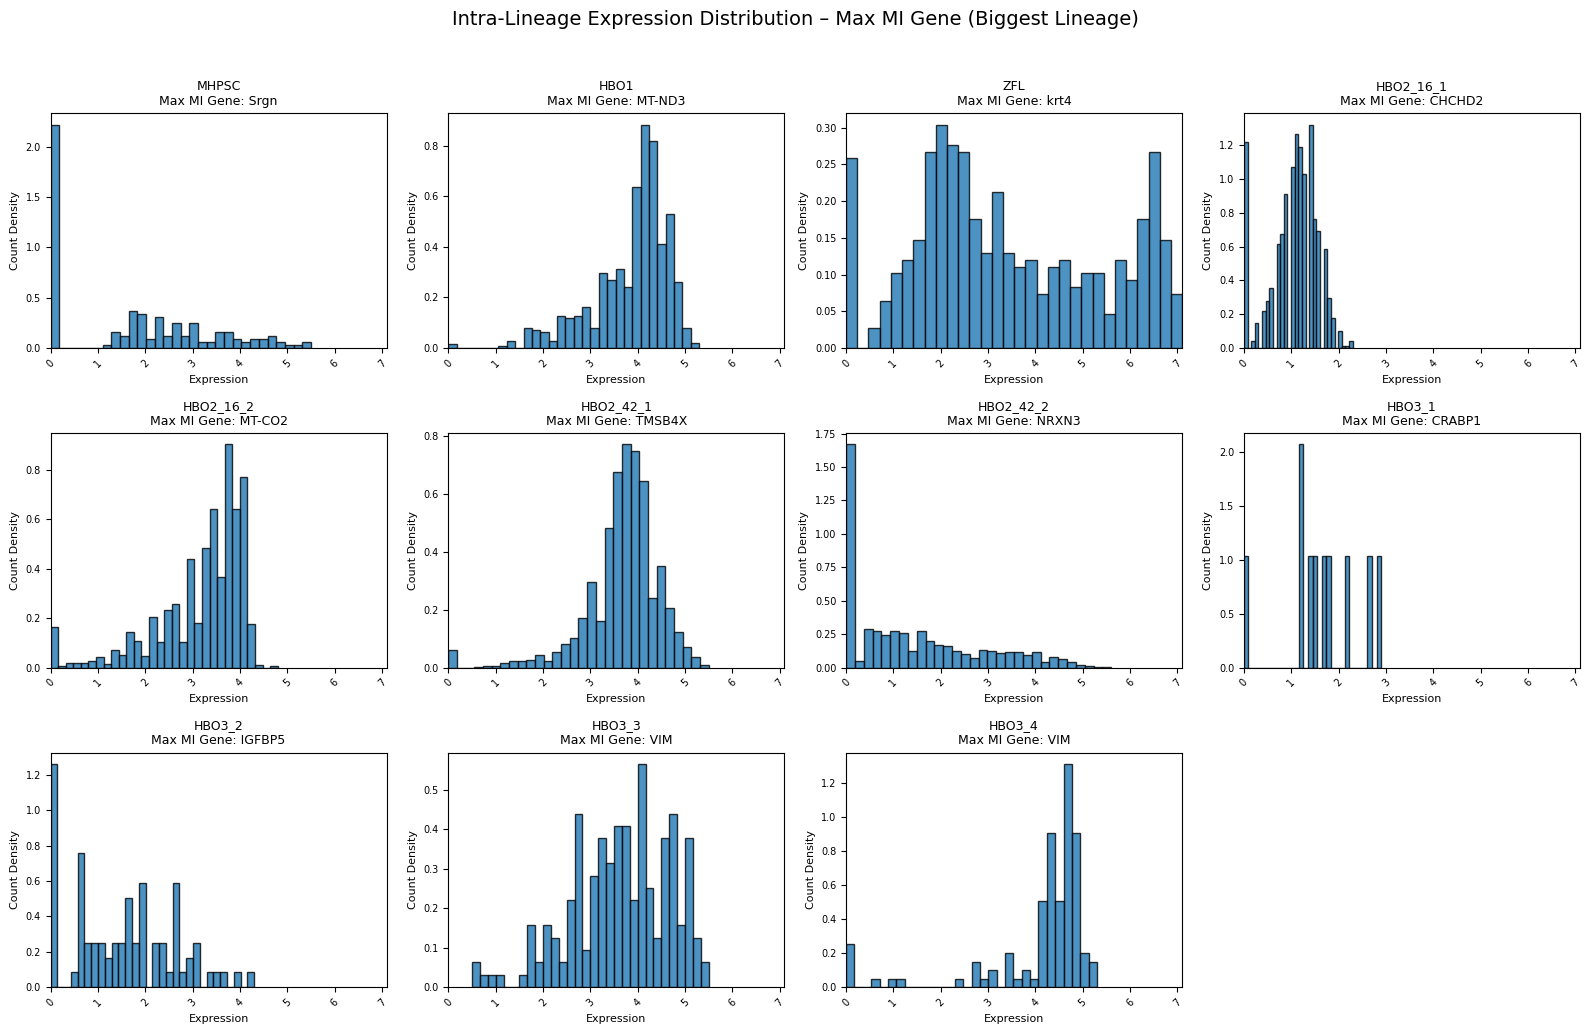

In [15]:
import scipy.stats as stats
import pickle
import numpy as np
import matplotlib.pyplot as plt

# --- Controls ---
ncols = 4  # number of subplot columns
nrows = int(np.ceil(len(file_dict) / ncols))

# --- First pass: find global x-axis max (for consistency) ---
global_max_val = 0
for dataset, path in file_dict.items():
    with open(path, "rb") as f:
        df = pickle.load(f)

    biggest_lineage_id = df["barcode_cont"].value_counts().idxmax()
    expr_df = df[df["barcode_cont"] == biggest_lineage_id].drop(columns=["barcode_cont"]).round(1)
    id_max_gene = normalized_mi_dict[dataset]["true_mi"].idxmax()
    gene_with_max_MI = normalized_mi_dict[dataset].iloc[id_max_gene]["gene"]
    expr_values = expr_df[gene_with_max_MI].to_numpy()

    if expr_values.size > 0:
        dataset_max = expr_values.max()
        if dataset_max > global_max_val:
            global_max_val = dataset_max

# --- Plot all datasets ---
plt.figure(figsize=(4*ncols, 3.5*nrows))

for i, (dataset, path) in enumerate(file_dict.items(), 1):
    with open(path, "rb") as f:
        df = pickle.load(f)

    biggest_lineage_id = df["barcode_cont"].value_counts().idxmax()
    expr_df = df[df["barcode_cont"] == biggest_lineage_id].drop(columns=["barcode_cont"]).round(1)
    id_max_gene = normalized_mi_dict[dataset]["true_mi"].idxmax()
    gene_with_max_MI = normalized_mi_dict[dataset].iloc[id_max_gene]["gene"]
    expr_values = expr_df[gene_with_max_MI].to_numpy()

    if expr_values.size == 0:
        continue

    plt.subplot(nrows, ncols, i)
    plt.hist(expr_values, bins=30, edgecolor="black", alpha=0.8, density=True)
    
    # Titles with mapping
    plt.title(f"{custom_titles.get(dataset, dataset)}\nMax MI Gene: {gene_with_max_MI}", fontsize=9)

    plt.xlabel("Expression", fontsize=8)
    plt.ylabel("Count Density", fontsize=8)
    plt.xlim(0, global_max_val)  # unified x-axis
    plt.xticks(rotation=45, fontsize=7)
    plt.yticks(fontsize=7)

plt.suptitle("Intra-Lineage Expression Distribution – Max MI Gene (Biggest Lineage)", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/intra_lineage_dists_all.pdf",
    bbox_inches="tight"
)
plt.show()


# --- Mean Expression per Lineage for Max MI Gene ---

In [16]:
import pandas as pd
import os

BASE = (
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/calc_files/MI/"
    "mi_analysis_results_MI_label_entropy_all_genes_parallel"
)

datasets = [
    "junker",
    "knoblich_day16_1", "knoblich_day16_2",
    "knoblich_day42_1", "knoblich_day42_2",
    "treutlein", "weinreb",
    "you1", "you2", "you3", "you4"
]

normalized_mi_dict = {}

for ds in datasets:
    path = os.path.join(BASE, f"MI_label_entropy_{ds}_50_permutations.csv")
    normalized_mi_dict[ds] = pd.read_csv(path)



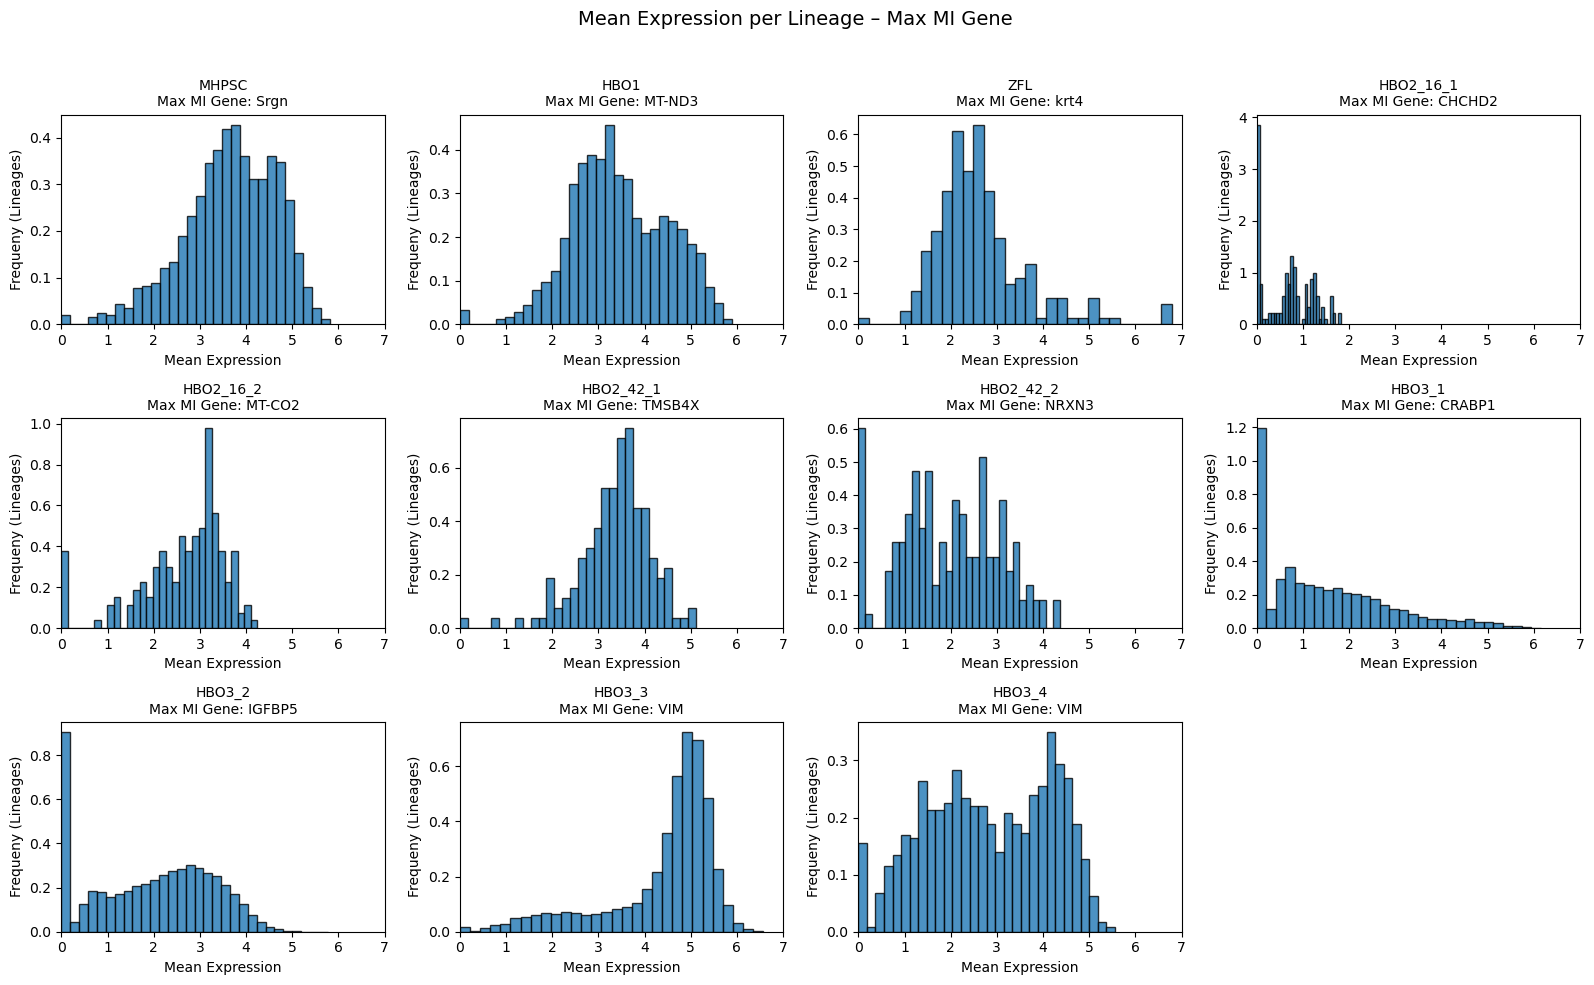

In [17]:
import seaborn as sns 
import matplotlib.pyplot as plt
import pickle
import numpy as np

# --- First pass: find global x-axis max ---
global_max = 0
for dataset, path in file_dict.items():
    with open(path, "rb") as f:
        df = pickle.load(f)
    
    id_max_gene = normalized_mi_dict[dataset]["true_mi"].idxmax()
    max_mi_gene = normalized_mi_dict[dataset].iloc[id_max_gene]["gene"]
    means = df[[max_mi_gene, "barcode_cont"]].groupby("barcode_cont").mean()[max_mi_gene].values
    dataset_max = means.max()
    if dataset_max > global_max:
        global_max = dataset_max

# Round up nicely
global_max = np.ceil(global_max)

# --- Plot histograms ---
plt.figure(figsize=(16, 10))

for i, (dataset, path) in enumerate(file_dict.items(), 1):
    with open(path, "rb") as f:
        df = pickle.load(f)
    id_max_gene = normalized_mi_dict[dataset]["true_mi"].idxmax()
    max_mi_gene = normalized_mi_dict[dataset].iloc[id_max_gene]["gene"]
    means = df[[max_mi_gene, "barcode_cont"]].groupby("barcode_cont").mean()[max_mi_gene].values

    plt.subplot(3, 4, i)  # adjust depending on number of datasets
    plt.hist(means, bins=30, edgecolor="black", alpha=0.8, density=True)
    plt.title(f"{custom_titles.get(dataset, dataset)}\nMax MI Gene: {max_mi_gene}", fontsize=10)
    plt.xlabel("Mean Expression")
    plt.ylabel("Frequeny (Lineages)")
    plt.xlim(0, global_max)   # <<< unified x-axis

plt.suptitle("Mean Expression per Lineage – Max MI Gene", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/mean_expression_per_lineage_distribution.pdf",
    bbox_inches="tight"
)
plt.show()


same for 3 selected subset 

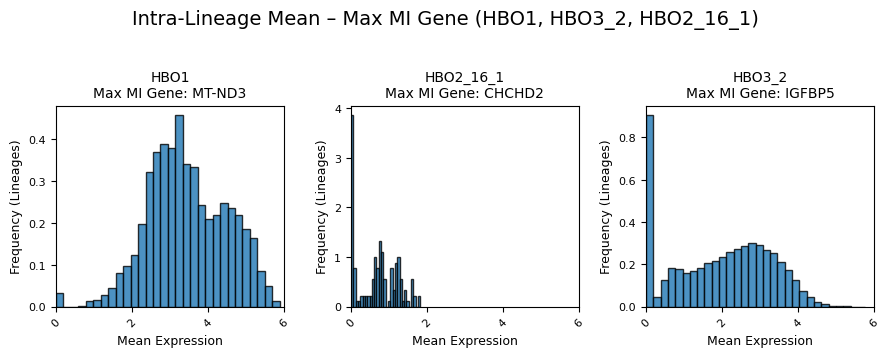

In [18]:
import matplotlib.pyplot as plt
import pickle
import numpy as np

wanted = {"HBO1", "HBO3_2", "HBO2_16_1"}
subset = [(ds, path) for ds, path in file_dict.items() if custom_titles.get(ds, ds) in wanted]

# --- First pass: global x-axis max over subset ---
global_max_mean = 0.0
for dataset, path in subset:
    with open(path, "rb") as f:
        df = pickle.load(f)
    id_max_gene = normalized_mi_dict[dataset]["true_mi"].idxmax()
    max_mi_gene = normalized_mi_dict[dataset].iloc[id_max_gene]["gene"]
    means = df[[max_mi_gene, "barcode_cont"]].groupby("barcode_cont").mean()[max_mi_gene].values
    if means.size:
        global_max_mean = max(global_max_mean, means.max())

global_max_mean = float(np.ceil(global_max_mean))

# --- Plot subset ---
n = len(subset)
ncols, nrows = 3, 1
plt.figure(figsize=(3*ncols, 3.6*nrows))

for i, (dataset, path) in enumerate(subset, 1):
    with open(path, "rb") as f:
        df = pickle.load(f)
    
    id_max_gene = normalized_mi_dict[dataset]["true_mi"].idxmax()
    max_mi_gene = normalized_mi_dict[dataset].iloc[id_max_gene]["gene"]
    means = df[[max_mi_gene, "barcode_cont"]].groupby("barcode_cont").mean()[max_mi_gene].values

    plt.subplot(nrows, ncols, i)
    plt.hist(means, bins=30, edgecolor="black", alpha=0.8, density=True)
    plt.title(f"{custom_titles.get(dataset, dataset)}\nMax MI Gene: {max_mi_gene}", fontsize=10)
    plt.xlabel("Mean Expression", fontsize=9)
    plt.ylabel("Frequency (Lineages)", fontsize=9)
    plt.xlim(0, global_max_mean)
    plt.xticks(rotation=45, fontsize=8)
    plt.yticks(fontsize=8)

plt.suptitle("Intra-Lineage Mean – Max MI Gene (HBO1, HBO3_2, HBO2_16_1)", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/mean_per_lineage_dist_subset.pdf", bbox_inches="tight")
plt.show()


# std deviation per lineage 

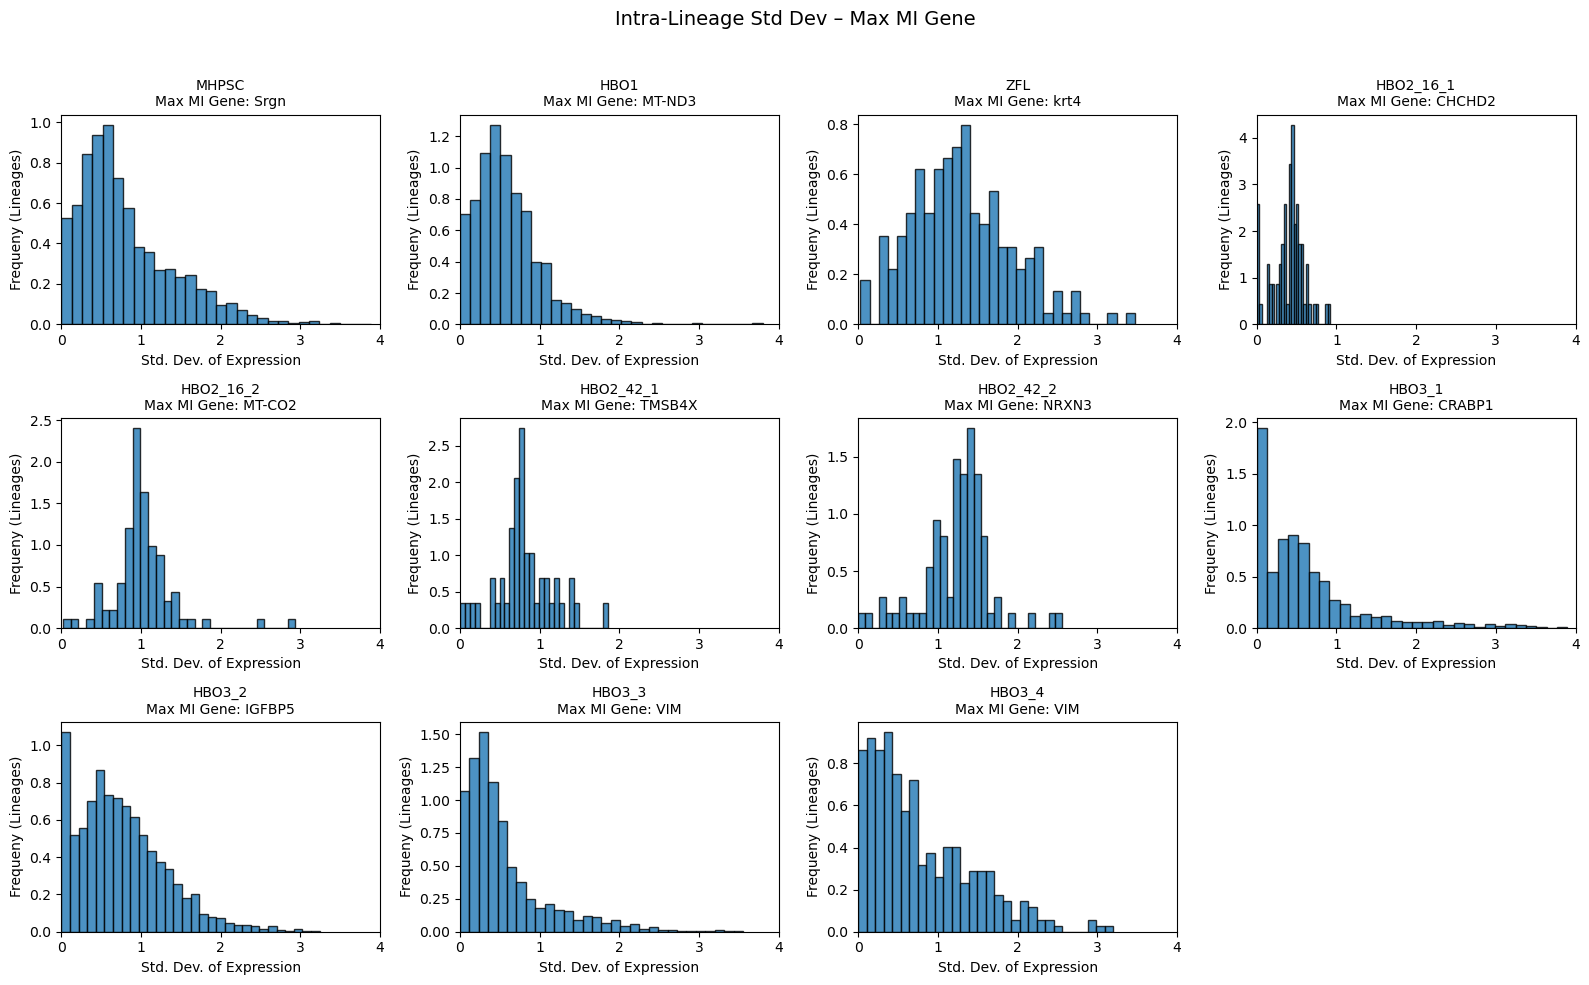

In [19]:
import matplotlib.pyplot as plt
import pickle
import numpy as np

# --- First pass: find global x-axis max ---
global_max_std = 0
for dataset, path in file_dict.items():
    with open(path, "rb") as f:
        df = pickle.load(f)
    id_max_gene = normalized_mi_dict[dataset]["true_mi"].idxmax()
    max_mi_gene = normalized_mi_dict[dataset].iloc[id_max_gene]["gene"]
    stds = df[[max_mi_gene, "barcode_cont"]].groupby("barcode_cont").std()[max_mi_gene].dropna().values
    dataset_max = stds.max() if len(stds) > 0 else 0
    if dataset_max > global_max_std:
        global_max_std = dataset_max

# Round up nicely
global_max_std = np.ceil(global_max_std)

# --- Plot histograms ---
plt.figure(figsize=(16, 10))

for i, (dataset, path) in enumerate(file_dict.items(), 1):
    with open(path, "rb") as f:
        df = pickle.load(f)
    id_max_gene = normalized_mi_dict[dataset]["true_mi"].idxmax()
    max_mi_gene = normalized_mi_dict[dataset].iloc[id_max_gene]["gene"]
    stds = df[[max_mi_gene, "barcode_cont"]].groupby("barcode_cont").std()[max_mi_gene].dropna().values

    plt.subplot(3, 4, i)  # adjust depending on number of datasets
    plt.hist(stds, bins=30, edgecolor="black", alpha=0.8, density=True)
    plt.title(f"{custom_titles.get(dataset, dataset)}\nMax MI Gene: {max_mi_gene}", fontsize=10)
    plt.xlabel("Std. Dev. of Expression")
    plt.ylabel("Frequeny (Lineages)")
    plt.xlim(0, global_max_std)  # <<< unified x-axis

plt.suptitle("Intra-Lineage Std Dev – Max MI Gene", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/std_per_lineage_dist.pdf",
    bbox_inches="tight"
)
plt.show()


only 3 for main figure 

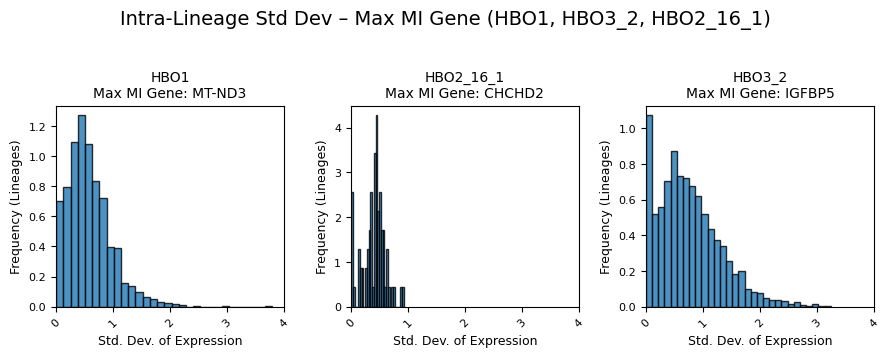

In [20]:
import matplotlib.pyplot as plt
import pickle
import numpy as np

wanted = {"HBO1", "HBO3_2", "HBO2_16_1"}
subset = [(ds, path) for ds, path in file_dict.items() if custom_titles.get(ds, ds) in wanted]

# --- First pass: global x-axis max over subset ---
global_max_std = 0.0
for dataset, path in subset:
    with open(path, "rb") as f:
        df = pickle.load(f)
    id_max_gene = normalized_mi_dict[dataset]["true_mi"].idxmax()
    max_mi_gene = normalized_mi_dict[dataset].iloc[id_max_gene]["gene"]
    stds = df[[max_mi_gene, "barcode_cont"]].groupby("barcode_cont").std()[max_mi_gene].dropna().values
    if stds.size:
        global_max_std = max(global_max_std, stds.max())

global_max_std = float(np.ceil(global_max_std))

# --- Plot subset ---
n = len(subset)
ncols, nrows = 3, 1  # 3 plots in one row
plt.figure(figsize=(3*ncols, 3.6*nrows))

for i, (dataset, path) in enumerate(subset, 1):
    with open(path, "rb") as f:
        df = pickle.load(f)

    id_max_gene = normalized_mi_dict[dataset]["true_mi"].idxmax()
    max_mi_gene = normalized_mi_dict[dataset].iloc[id_max_gene]["gene"]
    stds = df[[max_mi_gene, "barcode_cont"]].groupby("barcode_cont").std()[max_mi_gene].dropna().values

    plt.subplot(nrows, ncols, i)
    plt.hist(stds, bins=30, edgecolor="black", alpha=0.8, density=True)
    plt.title(f"{custom_titles.get(dataset, dataset)}\nMax MI Gene: {max_mi_gene}", fontsize=10)
    plt.xlabel("Std. Dev. of Expression", fontsize=9)
    plt.ylabel("Frequency (Lineages)", fontsize=9)
    plt.xlim(0, global_max_std)
    plt.xticks(rotation=45, fontsize=8)
    plt.yticks(fontsize=8)

plt.suptitle("Intra-Lineage Std Dev – Max MI Gene (HBO1, HBO3_2, HBO2_16_1)", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/std_per_lineage_dist_subset.pdf", bbox_inches="tight")
plt.show()


# distribution of entropy of gene expression per dataset

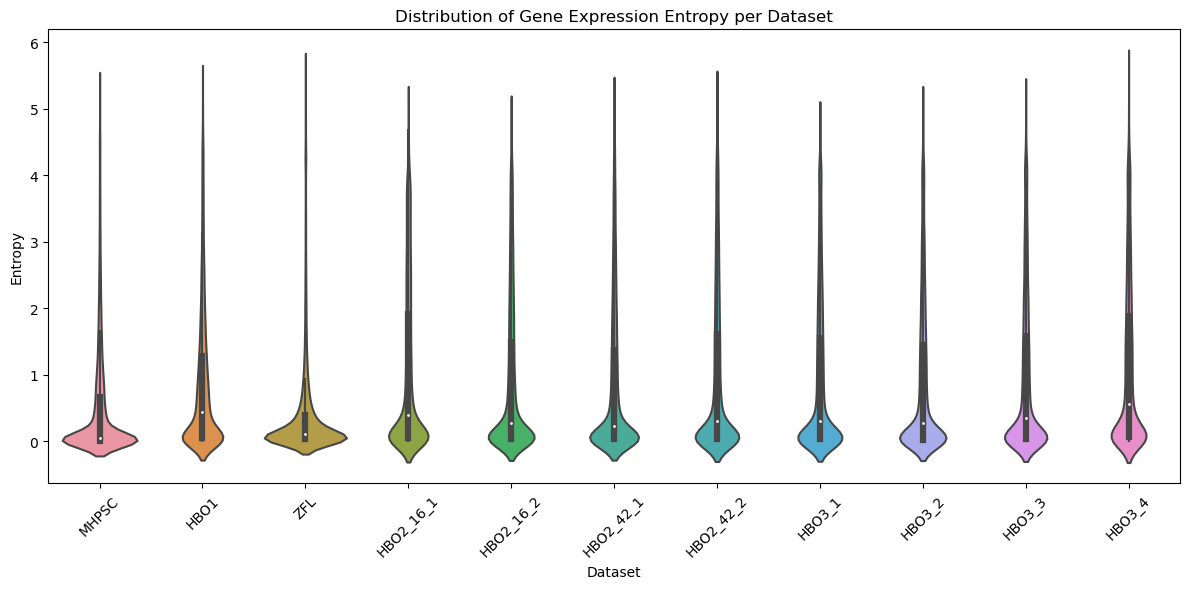

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

# Mapping titles and colors
custom_titles = {
    "knoblich_day16_1": "HBO2_16_1",
    "knoblich_day16_2": "HBO2_16_2",
    "knoblich_day42_1": "HBO2_42_1",
    "knoblich_day42_2": "HBO2_42_2",
    "weinreb": "MHPSC",
    "treutlein": "HBO1",
    "junker": "ZFL",
    "you1": "HBO3_1",
    "you2": "HBO3_2",
    "you3": "HBO3_3",
    "you4": "HBO3_4"
}

file_dict = {
    "weinreb": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/weinreb_all_genes.pkl",
    "treutlein": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/treutlein_all_genes.pkl",
    "junker": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/junker_z5_all_genes.pkl",

    "knoblich_day16_1": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day16_1.pkl",
    "knoblich_day16_2": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day16_2.pkl",
    "knoblich_day42_1": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day42_1.pkl",
    "knoblich_day42_2": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day42_2.pkl",

    "you1": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage1_barcode_all_genes.pkl",
    "you2": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage2_barcode_all_genes.pkl",
    "you3": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage3_barcode_all_genes.pkl",
    "you4": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage4_barcode_all_genes.pkl"
}


# Store entropy values
entropy_data = []

for name, path in file_dict.items():
    with open(path, "rb") as f:
        df = pickle.load(f)

    expr_df = df.drop(columns=["barcode_cont"])
    rounded_expr = expr_df.round(1)

    for gene in rounded_expr.columns:
        values = rounded_expr[gene].values
        vals, counts = np.unique(values, return_counts=True)
        probs = counts / counts.sum()
        entropy = -np.sum(probs * np.log2(probs))
        entropy_data.append({"Dataset": name, "Gene": gene, "Entropy": entropy})

# Create DataFrame
entropy_df = pd.DataFrame(entropy_data)
entropy_df["Dataset"] = entropy_df["Dataset"].map(custom_titles)

# Plot
plt.figure(figsize=(12, 6))
sns.violinplot(data=entropy_df, x="Dataset", y="Entropy", inner="box")
plt.xticks(rotation=45)
plt.title("Distribution of Gene Expression Entropy per Dataset")
plt.tight_layout()
plt.savefig("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/entropy_dist_of_expression.pdf", bbox_inches="tight")
plt.show()

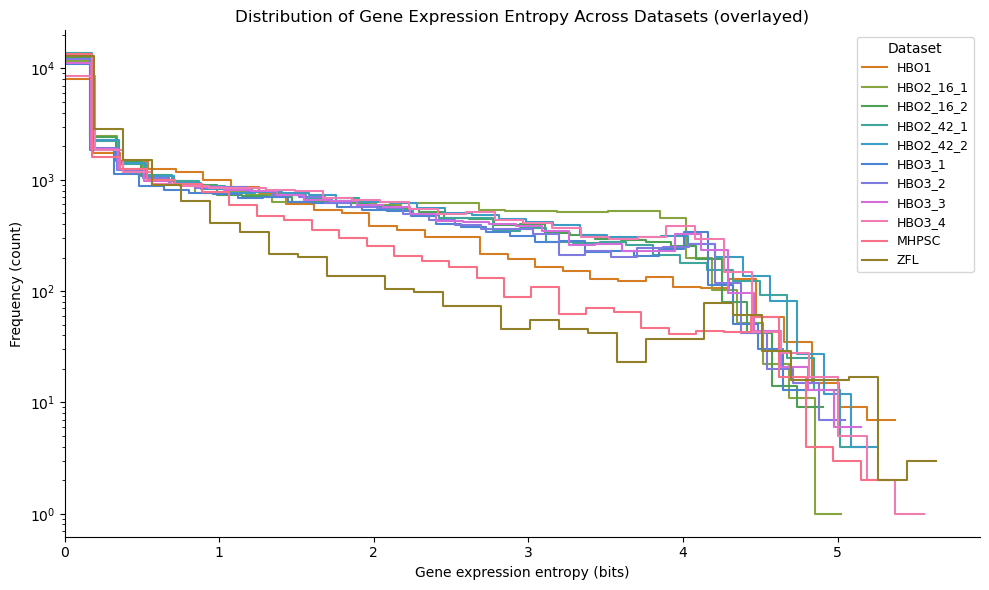

In [22]:

# ---------------------------
# Plot overlayed histograms
# ---------------------------


# Build dictionary of entropies per dataset
entropy_by_dataset = {
    d: group["Entropy"].values
    for d, group in entropy_df.groupby("Dataset")
}

color_map = {
    "MHPSC": "#f77189",      # weinreb
    "HBO1": "#d67c23",       # treutlein
    "ZFL": "#928029",        # junker
    "HBO2_16_1": "#87a441",  # knoblich_day16_1
    "HBO2_16_2": "#4ba255",  # knoblich_day16_2
    "HBO2_42_1": "#40a69b",  # knoblich_day42_1
    "HBO2_42_2": "#3c9dc4",  # knoblich_day42_2
    "HBO3_1": "#4b85d2",     # you1
    "HBO3_2": "#7f7ae0",     # you2
    "HBO3_3": "#d46cd9",     # you3
    "HBO3_4": "#f17cb0"      # you4
}


plt.figure(figsize=(10, 6))

for name, entropies in entropy_by_dataset.items():
    # Filter zeros for log x
    ent_pos = entropies[entropies > 0]
    if ent_pos.size == 0:
        warnings.warn(f"No positive entropies for dataset {name}; skipping in log-x plot.")
        continue

    sns.histplot(
        ent_pos,
        bins=30,
        kde=False,
        stat="count",
        element="step",
        fill=False,
        alpha=1,
        label=custom_titles.get(name, name),
        color=color_map.get(name, "gray")
    )

sns.despine()
plt.yscale("log")
plt.xlim(0)

plt.xlabel("Gene expression entropy (bits)")
plt.ylabel("Frequency (count)")
plt.legend(title="Dataset", fontsize=9)
plt.title("Distribution of Gene Expression Entropy Across Datasets (overlayed)")
plt.tight_layout()
plt.savefig(
    "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/entropy_overlayed_hist_loglog.pdf",
    bbox_inches="tight"
)
plt.show()


# plotting max unique expression states and theory curve

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Mapping of internal names to custom display titles
pretty_names = {
    "treutlein": "HBO1",
    "junker": "ZFL",
    "weinreb": "MHPSC",
    "knoblich_day16_1": "HBO2_16_1",
    "knoblich_day16_2": "HBO2_16_2",
    "knoblich_day42_1": "HBO2_42_1",
    "knoblich_day42_2": "HBO2_42_2",
    "you1": "HBO3_1",
    "you2": "HBO3_2",
    "you3": "HBO3_3",
    "you4": "HBO3_4"
}

def plot_log_exp_states(df, x="unique_expr_vals_max_MI_gene", y="max_MI"):
    df = df.copy()
    df["pretty_name"] = df["dataset"].map(pretty_names)

    plt.figure(figsize=(7, 5))
    sns.scatterplot(data=df, x=x, y=y, hue="pretty_name", s=80)

    x_vals = np.linspace(1, df[x].max(), 200)
    y_theory = np.log2(x_vals)

    plt.plot(x_vals, y_theory, '--', color='black', linewidth=2,
             label=r"$\log_2(\mathrm{number\ of\ expression\ states})$")
    plt.xlabel("Number of unique expression states")
    plt.ylabel("Max Mutual Information")
    plt.title("Max MI vs Number of Unique Expression States")
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", title="Dataset")
    sns.despine()
    plt.grid(False)
    plt.tight_layout()
    plt.savefig("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/theory_lineages_vs_MI.pdf", bbox_inches="tight")
    plt.show()


In [24]:
dfs = [
    normalized_MI_treutlein,
    normalized_MI_junker,
    normalized_MI_weinreb,
    normalized_MI_knoblich_day16_1,
    normalized_MI_knoblich_day16_2,
    normalized_MI_knoblich_day42_1,
    normalized_MI_knoblich_day42_2,
    normalized_MI_you1,
    normalized_MI_you2,
    normalized_MI_you3,
    normalized_MI_you4
]

# Apply drop_duplicates to each DataFrame
dfs = [df.drop_duplicates(subset="gene", keep="first") for df in dfs]

for df in dfs:
    df["is_sign"] = df["true_mi"] > df["95_perm_mi"]

# Reassign the cleaned DataFrames back to the original variable names
(
    normalized_MI_treutlein,
    normalized_MI_junker,
    normalized_MI_weinreb,
    normalized_MI_knoblich_day16_1,
    normalized_MI_knoblich_day16_2,
    normalized_MI_knoblich_day42_1,
    normalized_MI_knoblich_day42_2,
    normalized_MI_you1,
    normalized_MI_you2,
    normalized_MI_you3,
    normalized_MI_you4
) = dfs

/tmp/ipykernel_2158/1429953020.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["is_sign"] = df["true_mi"] > df["95_perm_mi"]


In [4]:
normalized_mi_dict = {
    "treutlein": normalized_MI_treutlein,
    "junker": normalized_MI_junker,
    "weinreb": normalized_MI_weinreb,
    "knoblich_day16_1": normalized_MI_knoblich_day16_1,
    "knoblich_day16_2": normalized_MI_knoblich_day16_2,
    "knoblich_day42_1": normalized_MI_knoblich_day42_1,
    "knoblich_day42_2": normalized_MI_knoblich_day42_2,
    "you1": normalized_MI_you1,
    "you2": normalized_MI_you2,
    "you3": normalized_MI_you3,
    "you4": normalized_MI_you4
}


In [26]:
import pickle
import numpy as np
import pandas as pd
from scipy.stats import entropy

summary_stats = []

for dataset, path in file_dict.items():
    with open(path, "rb") as f:
        df = pickle.load(f)
        
    total_cells = df.shape[0]
    lineage_counts = df["barcode_cont"].value_counts()
    num_lineages = lineage_counts.size
    avg_cells_per_lineage = lineage_counts.mean()
    med_cells_per_lineage = lineage_counts.median()

    expr_df = df.drop(columns=["barcode_cont"]).round(1)
    gene_ranges = (expr_df.max() - expr_df.min())
    avg_gene_range = gene_ranges.mean()
    med_gene_range = gene_ranges.median()

    # MI dataframe for the current dataset
    mi_df = normalized_mi_dict[dataset]
    mi_series = mi_df["true_mi"]

    max_MI = mi_series.max()
    id_gene_with_max_MI = mi_series.idxmax()
    gene_with_max_MI = mi_df.loc[id_gene_with_max_MI, "gene"]

    # Mean MI and % significant
    mean_true_mi = mi_series.mean()
    percent_significant = mi_df["is_sign"].mean() * 100

    # Entropy of expression distribution for max MI gene
    expr_values = expr_df[gene_with_max_MI]
    value_counts = expr_values.value_counts(normalize=True)
    expr_entropy = entropy(value_counts, base=2)

    summary_stats.append({
        "dataset": dataset,
        "num_cells": total_cells,
        "num_lineages": num_lineages,
        "mean_cells_per_lineage": avg_cells_per_lineage,
        "median_cells_per_lineage": med_cells_per_lineage,
        "mean_gene_range": avg_gene_range,
        "median_gene_range": med_gene_range,
        "max_MI": max_MI,
        "unique_expr_vals_max_MI_gene": expr_values.nunique(),
        "expr_entropy_max_MI_gene": expr_entropy,
        "mean_true_mi": mean_true_mi,
        "percent_sign": percent_significant
    })

summary_df = pd.DataFrame(summary_stats)


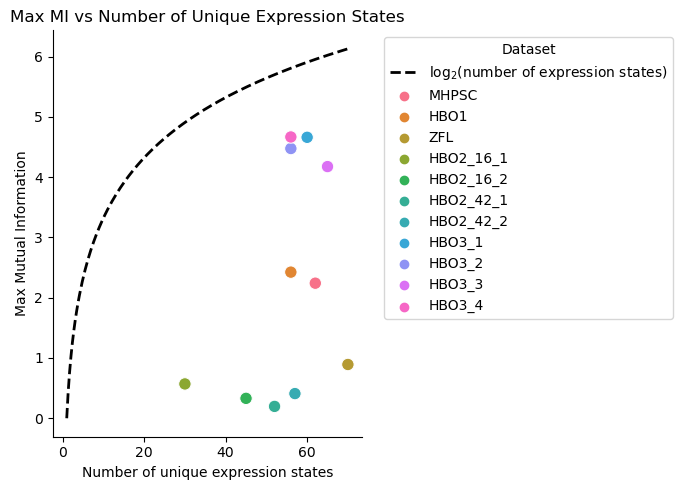

In [27]:
plot_log_exp_states(summary_df)

In [28]:
summary_df

,dataset,num_cells,num_lineages,mean_cells_per_lineage,median_cells_per_lineage,mean_gene_range,median_gene_range,max_MI,unique_expr_vals_max_MI_gene,expr_entropy_max_MI_gene,mean_true_mi,percent_sign
0,weinreb,49302,5864,8.407572,4.0,2.939084,3.1,2.240673,62,5.328182,0.204429,39.808270
1,treutlein,16506,3905,4.226889,1.0,2.146855,2.1,2.424044,56,5.338045,0.339048,63.113732
2,junker,6191,210,29.480952,7.0,2.345656,2.3,0.891865,70,5.638932,0.073071,12.643624
3,knoblich_day16_1,5695,149,38.221477,2.0,1.830131,2.0,0.569293,30,3.780207,0.067667,10.069930
4,knoblich_day16_2,8730,188,46.436170,1.5,2.148420,2.5,0.330191,45,4.760882,0.054744,8.744077
5,knoblich_day42_1,9533,157,60.719745,1.0,2.209549,2.3,0.196572,52,4.812243,0.030774,10.007242
6,knoblich_day42_2,8109,160,50.681250,2.0,1.872239,1.8,0.409201,57,4.805918,0.055316,22.449050
7,you1,18650,17075,1.092240,1.0,1.643260,1.6,4.661076,60,4.805089,0.877577,53.761490
8,you2,42640,33308,1.280173,1.0,1.825501,1.8,4.474936,56,5.010637,0.760812,64.091011
9,you3,23883,15792,1.512348,1.0,1.783609,1.8,4.175572,65,5.148217,0.736366,43.416699


# percentage of sign genes 

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import pearsonr

def plot_sign_genes_vs_mean_mi(summary_df):
    """
    Plots percentage of significant genes vs mean true MI with Pearson correlation.

    Parameters
    ----------
    summary_df : pd.DataFrame
        Must contain 'percent_sign' and 'mean_true_mi' columns.
    """
    plt.figure(figsize=(7, 5))

    # Scatter plot
    sns.scatterplot(
        data=summary_df,
        x="percent_sign",
        y="mean_true_mi",
        hue="dataset",  # optional
        s=80
    )

    # Compute Pearson correlation
    r, pval = pearsonr(summary_df["percent_sign"], summary_df["mean_true_mi"])
    print(r)
    print(pval)

    # Add simple linear fit line for visualization
    x_vals = np.linspace(summary_df["percent_sign"].min(), summary_df["percent_sign"].max(), 100)
    y_vals = np.poly1d(np.polyfit(summary_df["percent_sign"], summary_df["mean_true_mi"], 1))(x_vals)
    plt.plot(x_vals, y_vals, linestyle='--', linewidth=2)

    # Add text box with Pearson r
    plt.text(
        0.05, 0.95,
        f"Pearson r = {r:.3f}\np = {pval:.3e}",
        transform=plt.gca().transAxes,
        verticalalignment='top',
        bbox=dict(boxstyle="round", alpha=0.3)
    )

    # Labels and title
    plt.xlabel("Percentage of Significant Genes")
    plt.ylabel("Mean True MI")
    plt.title("Significant Genes vs Mean True MI")
    plt.tight_layout()

    # Save and show
    plt.savefig(
        "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/sin_percentage_vs_mean_true_mi.pdf",
        bbox_inches="tight"
    )
    plt.show()


In [30]:
summary_df

,dataset,num_cells,num_lineages,mean_cells_per_lineage,median_cells_per_lineage,mean_gene_range,median_gene_range,max_MI,unique_expr_vals_max_MI_gene,expr_entropy_max_MI_gene,mean_true_mi,percent_sign
0,weinreb,49302,5864,8.407572,4.0,2.939084,3.1,2.240673,62,5.328182,0.204429,39.808270
1,treutlein,16506,3905,4.226889,1.0,2.146855,2.1,2.424044,56,5.338045,0.339048,63.113732
2,junker,6191,210,29.480952,7.0,2.345656,2.3,0.891865,70,5.638932,0.073071,12.643624
3,knoblich_day16_1,5695,149,38.221477,2.0,1.830131,2.0,0.569293,30,3.780207,0.067667,10.069930
4,knoblich_day16_2,8730,188,46.436170,1.5,2.148420,2.5,0.330191,45,4.760882,0.054744,8.744077
5,knoblich_day42_1,9533,157,60.719745,1.0,2.209549,2.3,0.196572,52,4.812243,0.030774,10.007242
6,knoblich_day42_2,8109,160,50.681250,2.0,1.872239,1.8,0.409201,57,4.805918,0.055316,22.449050
7,you1,18650,17075,1.092240,1.0,1.643260,1.6,4.661076,60,4.805089,0.877577,53.761490
8,you2,42640,33308,1.280173,1.0,1.825501,1.8,4.474936,56,5.010637,0.760812,64.091011
9,you3,23883,15792,1.512348,1.0,1.783609,1.8,4.175572,65,5.148217,0.736366,43.416699


0.7514062723274426
0.0076725744283120765


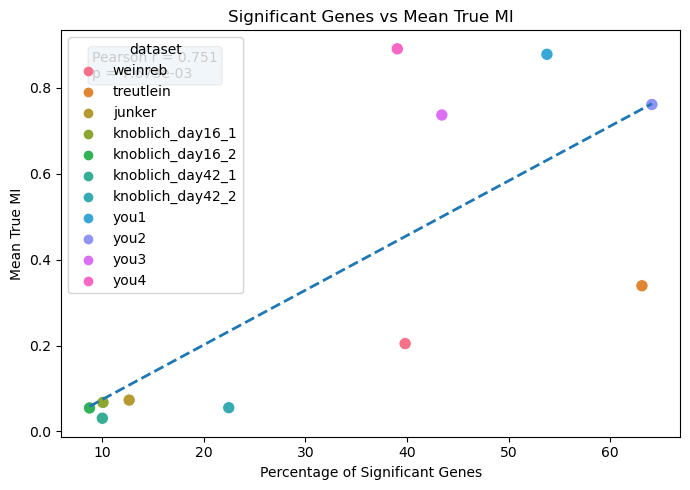

In [31]:
plot_sign_genes_vs_mean_mi(summary_df)

# mean intra lineage entropy of expression for Max MI gene

In [6]:

import pickle 
import numpy as np

from scipy.stats import entropy

summary_data = []

for dataset, path in file_dict.items():
    with open(path, "rb") as f:
        df = pickle.load(f)

    mi_df = normalized_mi_dict[dataset]
    mi_series = mi_df["true_mi"]

    max_MI = mi_series.max()
    id_gene_with_max_MI = mi_series.idxmax()
    gene = mi_df.loc[id_gene_with_max_MI, "gene"]

    lineage_entropies = []
    for _, group in df.groupby("barcode_cont"):
        expr_vals = np.round(group[gene], 1)
        value_counts = expr_vals.value_counts(normalize=True)
        if len(value_counts) > 1:
            H = entropy(value_counts, base=2)
            lineage_entropies.append(H)

    if lineage_entropies:
        mean_H = np.mean(lineage_entropies)
    else:
        mean_H = np.nan

    summary_data.append({
        "dataset": dataset,
        "max_MI": max_MI,
        "mean_intra_lineage_entropy": mean_H
    })

summary_df = pd.DataFrame(summary_data)


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import pearsonr



# Mapping of internal names to pretty labels
pretty_names = {
    "treutlein": "HBO1",
    "junker": "ZFL",
    "weinreb": "MHPSC",
    "knoblich_day16_1": "HBO2_16_1",
    "knoblich_day16_2": "HBO2_16_2",
    "knoblich_day42_1": "HBO2_42_1",
    "knoblich_day42_2": "HBO2_42_2",
    "you1": "HBO3_1",
    "you2": "HBO3_2",
    "you3": "HBO3_3",
    "you4": "HBO3_4"
}

def plot_intra_lineage_entropy(summary_df):
    summary_df = summary_df.copy()
    summary_df["pretty_name"] = summary_df["dataset"].map(pretty_names)
    
        # Pearson correlation
    r, p = pearsonr(
        summary_df["mean_intra_lineage_entropy"],
        summary_df["max_MI"]
    )

    print(f"Pearson r = {r:.3f}, p = {p:.3e}")


    plt.figure(figsize=(7, 5))

    sns.scatterplot(
        data=summary_df,
        x="mean_intra_lineage_entropy",
        y="max_MI",
        hue="pretty_name",
        s=80
    )

    # Theoretical inverse trend: I ~ -H (scaled)
    x_vals = np.linspace(summary_df["mean_intra_lineage_entropy"].min(),
                         summary_df["mean_intra_lineage_entropy"].max(), 200)
    y_theory = -x_vals
    y_scaled = (y_theory - y_theory.min()) / (y_theory.max() - y_theory.min())
    y_scaled *= summary_df["max_MI"].max()

    plt.plot(x_vals, y_scaled, '--', color='black', linewidth=2,
             label=r"$I_{\max} \sim - \mathcal{H}_{\mathrm{intra-lineage}}$")

    plt.xlabel("Mean Intra-Lineage Entropy")
    plt.ylabel("Max Mutual Information")
    plt.title("Max MI vs Intra-Lineage Entropy")
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", title="Dataset")
    sns.despine()
    plt.grid(False)
    plt.tight_layout()
    plt.savefig("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/Intra_lineage_entropy_vs_MI.pdf", bbox_inches="tight")
    plt.show()


Pearson r = -0.974, p = 4.397e-07


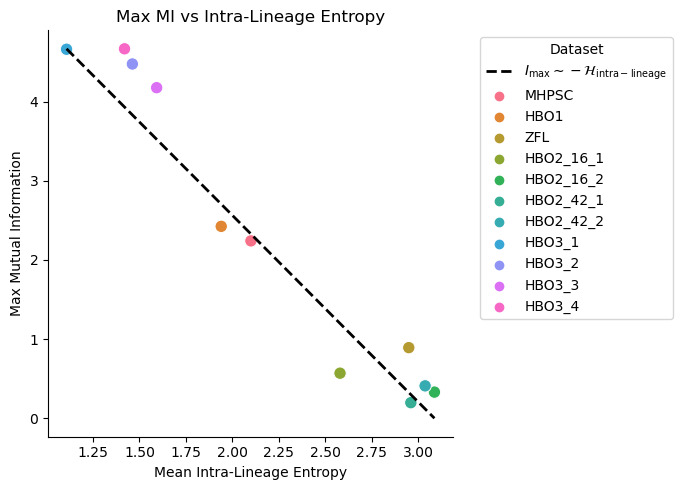

In [10]:
plot_intra_lineage_entropy(summary_df)

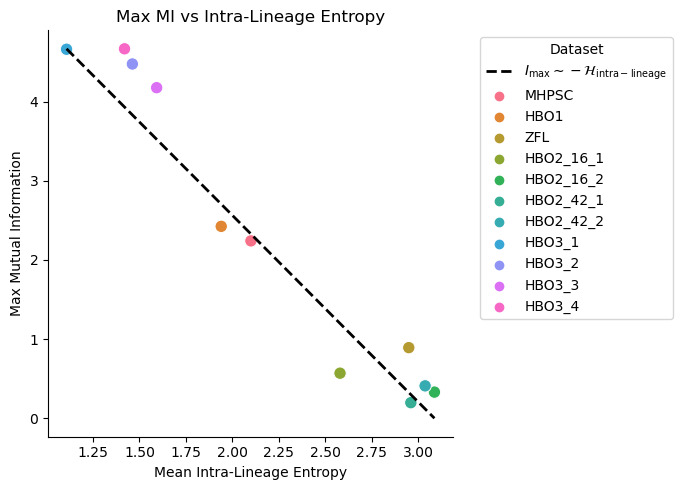

In [34]:
plot_intra_lineage_entropy(summary_df)

# simulated MI vs number of unique lineages plot

In [35]:
file_dict = {
    "weinreb": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/weinreb_all_genes.pkl",
    "treutlein": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/treutlein_all_genes.pkl",
    "junker": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/junker_z5_all_genes.pkl",

    "knoblich_day16_1": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day16_1.pkl",
    "knoblich_day16_2": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day16_2.pkl",
    "knoblich_day42_1": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day42_1.pkl",
    "knoblich_day42_2": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day42_2.pkl",

    "you1": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage1_barcode_all_genes.pkl",
    "you2": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage2_barcode_all_genes.pkl",
    "you3": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage3_barcode_all_genes.pkl",
    "you4": "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/you_stage4_barcode_all_genes.pkl"
}

In [36]:
import pandas as pd
import os

BASE = (
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/calc_files/MI/"
    "mi_analysis_results_MI_label_entropy_all_genes_parallel"
)

datasets = [
    "junker",
    "knoblich_day16_1", "knoblich_day16_2",
    "knoblich_day42_1", "knoblich_day42_2",
    "treutlein", "weinreb",
    "you1", "you2", "you3", "you4"
]

normalized_mi_dict = {}

for ds in datasets:
    path = os.path.join(BASE, f"MI_label_entropy_{ds}_50_permutations.csv")
    normalized_mi_dict[ds] = pd.read_csv(path)



In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numba import njit

def simulate_lineages_log_normal(N_total, n_lineages, sigma=1.5, seed=0):
    seed = (seed + int(sigma * 1000) + n_lineages) % (2**32)
    np.random.seed(seed)

    # Generate raw log-normal values
    mu = np.log(N_total / n_lineages) - sigma**2 / 2
    raw = np.random.lognormal(mean=mu, sigma=sigma, size=n_lineages)

    # Normalize to sum to total
    normalized = raw / raw.sum() * N_total
    sizes = np.round(normalized).astype(int)

    # --- Enforce minimum of 1 cell per lineage ---
    sizes[sizes < 1] = 1

    # --- Adjust total to exactly N_total ---
    delta = N_total - sizes.sum()

    # Distribute delta
    while delta != 0:
        if delta > 0:
            idx = np.random.choice(len(sizes))
            sizes[idx] += 1
            delta -= 1
        else:
            idxs = np.where(sizes > 1)[0]  # never reduce below 1
            if len(idxs) == 0:
                break  # all are 1, can't reduce
            idx = np.random.choice(idxs)
            sizes[idx] -= 1
            delta += 1

    return sizes



In [38]:
def lineage_entropy(sizes):
    p = sizes / sizes.sum()
    return -np.sum(p * np.log2(p))

def generate_theory_entropy_curves(n_lineages_range=range(100, 35000, 1000),
                                   sigmas=[0.5, 1.0, 1.5, 2.0, 2.5],
                                   avg_cells_per_lineage=100):
    rows = []
    for sigma in sigmas:
        for n_lineages in n_lineages_range:
            n_total = n_lineages * avg_cells_per_lineage
            sizes = simulate_lineages_log_normal(n_total, n_lineages, sigma=sigma, seed=42)
            H = lineage_entropy(sizes)
            rows.append({
                "num_lineages": n_lineages,
                "max_MI": H,
                "skew_label": f"σ_lineage = {sigma:.1f}"
            })
    return pd.DataFrame(rows)

# --- Recreate theory_df
theory_df = generate_theory_entropy_curves()


In [39]:
color_map = {
    "weinreb": "#f77189",
    "treutlein": "#d67c23",
    "junker": "#928029",
    "knoblich_day16_1": "#87a441",
    "knoblich_day16_2": "#4ba255",
    "knoblich_day42_1": "#40a69b",
    "knoblich_day42_2": "#3c9dc4",
    "you1": "#4b85d2",
    "you2": "#7f7ae0",
    "you3": "#d46cd9",
    "you4": "#f17cb0"
}

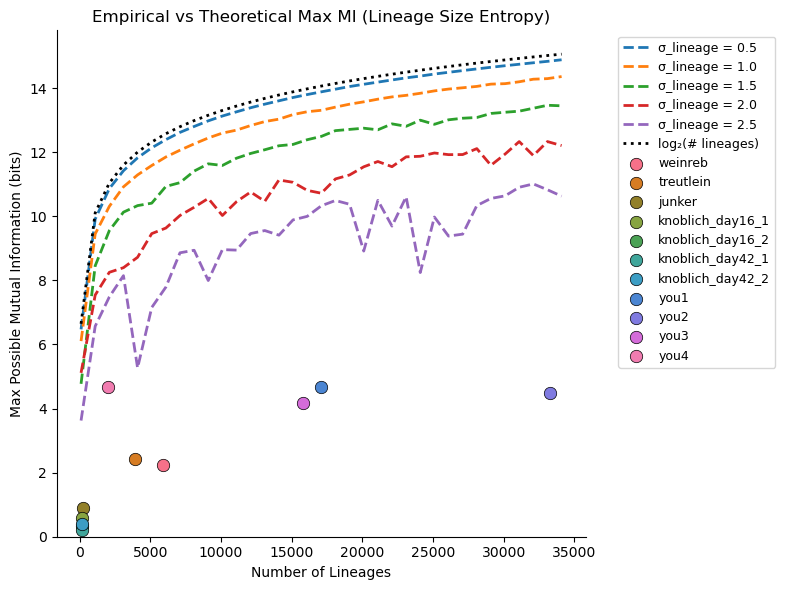

In [40]:
import seaborn as sns 

plt.figure(figsize=(8, 6))

# --- Theory curves ---
for label, subdf in theory_df.groupby("skew_label"):
    subdf_sorted = subdf.sort_values("num_lineages")
    plt.plot(subdf_sorted["num_lineages"], subdf_sorted["max_MI"],
             label=label, linestyle="--", linewidth=2)

# --- Add log2(num_lineages) as max MI without skew ---
n_range = theory_df["num_lineages"].unique()
log_mi = np.log2(n_range)
plt.plot(n_range, log_mi, label="log₂(# lineages)", color="black", linestyle=":", linewidth=2)

# --- Overlay empirical max MI dotplot ---
for dataset, path in file_dict.items():
    with open(path, "rb") as f:
        df = pickle.load(f)

    num_lineages = df["barcode_cont"].nunique()
    max_mi = normalized_mi_dict[dataset]["true_mi"].max()
    color = color_map.get(dataset, "gray")

    plt.scatter(num_lineages, max_mi, label=dataset, color=color, s=80, edgecolor="black", linewidth=0.5)

# --- Aesthetics ---
plt.xlabel("Number of Lineages")
plt.ylabel("Max Possible Mutual Information (bits)")
plt.title("Empirical vs Theoretical Max MI (Lineage Size Entropy)")
plt.ylim(bottom=0)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=9)
plt.tight_layout()
sns.despine()
plt.grid(False)
plt.savefig("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/simulation_MI_vs_Num_lin.pdf", bbox_inches="tight")
plt.show()


# theoretical curves

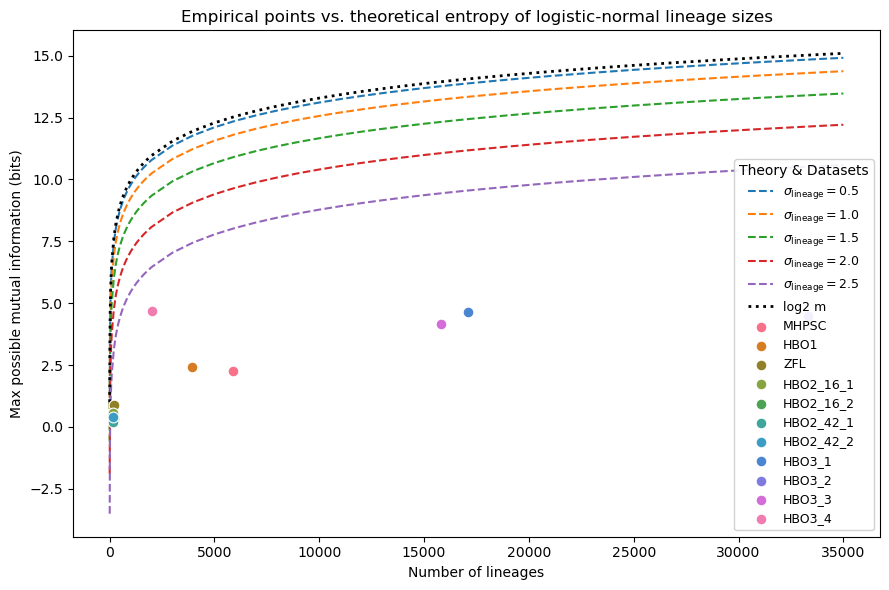

In [41]:
import numpy as np
import matplotlib.pyplot as plt
import pickle

# ---------- Theory ----------
def H_logistic_normal_theory(m, sigma):
    # E[H] ≈ log2 m − σ^2/(2 ln 2)
    return np.log2(m) - (sigma**2)/(2*np.log(2))

sigmas = [0.5, 1.0, 1.5, 2.0, 2.5]
m_vals = np.unique(np.concatenate([
    np.arange(2, 101),
    np.arange(100, 2001, 100),
    np.arange(2000, 35001, 1000)
]))

# ---------- Pretty names and colors (from our previous sessions) ----------
custom_titles = {
    "knoblich_day16_1": "HBO2_16_1",
    "knoblich_day16_2": "HBO2_16_2",
    "knoblich_day42_1": "HBO2_42_1",
    "knoblich_day42_2": "HBO2_42_2",
    "weinreb": "MHPSC",
    "treutlein": "HBO1",
    "junker": "ZFL",
    "you1": "HBO3_1",
    "you2": "HBO3_2",
    "you3": "HBO3_3",
    "you4": "HBO3_4"
}

color_map = {
    "MHPSC": "#f77189",
    "HBO1": "#d67c23",
    "ZFL": "#928029",
    "HBO2_16_1": "#87a441",
    "HBO2_16_2": "#4ba255",
    "HBO2_42_1": "#40a69b",
    "HBO2_42_2": "#3c9dc4",
    "HBO3_1": "#4b85d2",
    "HBO3_2": "#7f7ae0",
    "HBO3_3": "#d46cd9",
    "HBO3_4": "#f17cb0"
}

plt.figure(figsize=(9, 6))

# Theory family
for s in sigmas:
    plt.plot(m_vals, H_logistic_normal_theory(m_vals, s),
             linestyle='--', label=fr'$\sigma_{{\mathrm{{lineage}}}}={s}$')

# Baseline ceiling
plt.plot(m_vals, np.log2(m_vals), linestyle=':', linewidth=2, color='k', label='log2 m')

# ---------- Overlay empirical points ----------
# Expect: file_dict and normalized_mi_dict already defined in your session
for ds_key, path in file_dict.items():
    # load dataframe to count lineages
    with open(path, "rb") as f:
        df = pickle.load(f)
    m_emp = df["barcode_cont"].nunique()

    # pull "best" MI from your per-gene MI table
    mi_df = normalized_mi_dict[ds_key]
    if "true_mi" in mi_df.columns:
        mi_series = mi_df["true_mi"]
    elif "mutual information" in mi_df.columns:
        mi_series = mi_df["mutual information"]
    else:
        raise KeyError(f"No MI column found for dataset {ds_key}")
    mi_emp = float(mi_series.max())

    # cosmetics
    name = custom_titles.get(ds_key, ds_key)
    c = color_map.get(name, None)

    plt.scatter(m_emp, mi_emp, s=60, edgecolor='white', linewidth=0.8, label=name, color=c, zorder=3)

# Labeling
plt.xlabel('Number of lineages')
plt.ylabel('Max possible mutual information (bits)')
plt.title('Empirical points vs. theoretical entropy of logistic-normal lineage sizes')

# Single combined legend (theory + datasets + log2 m)
plt.legend(loc='best', fontsize=9, framealpha=0.9, title='Theory & Datasets')

plt.tight_layout()
plt.show()


# both plot in one 

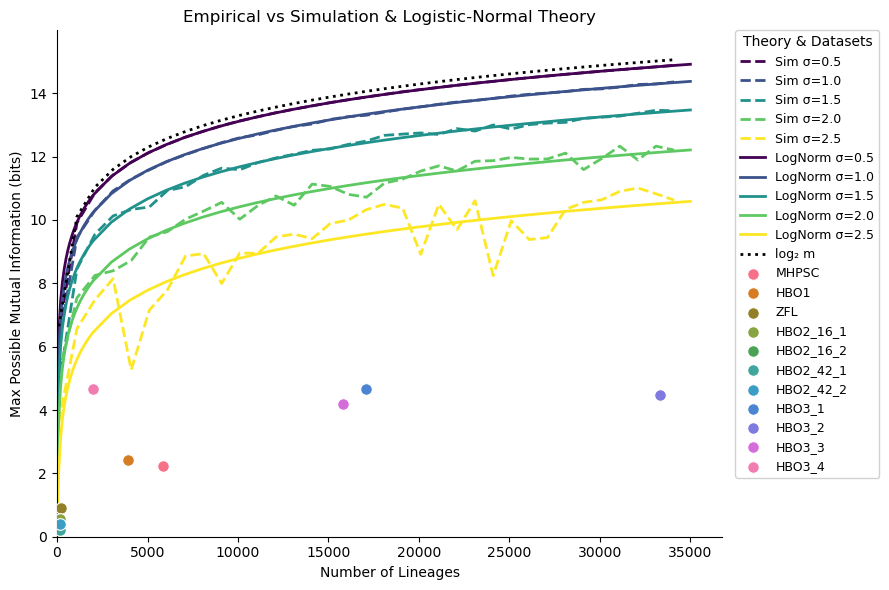

In [42]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

# ---------- Functions ----------
def H_logistic_normal_theory(m, sigma):
    return np.log2(m) - (sigma**2)/(2*np.log(2))

# ---------- Settings ----------
sigmas = [0.5, 1.0, 1.5, 2.0, 2.5]
sigma_colors = dict(zip(sigmas, plt.cm.viridis(np.linspace(0, 1, len(sigmas)))))

m_vals = np.unique(np.concatenate([
    np.arange(2, 101),
    np.arange(100, 2001, 100),
    np.arange(2000, 35001, 1000)
]))

# Pretty names and dataset colors
custom_titles = {
    "knoblich_day16_1": "HBO2_16_1",
    "knoblich_day16_2": "HBO2_16_2",
    "knoblich_day42_1": "HBO2_42_1",
    "knoblich_day42_2": "HBO2_42_2",
    "weinreb": "MHPSC",
    "treutlein": "HBO1",
    "junker": "ZFL",
    "you1": "HBO3_1",
    "you2": "HBO3_2",
    "you3": "HBO3_3",
    "you4": "HBO3_4"
}

color_map = {
    "MHPSC": "#f77189",
    "HBO1": "#d67c23",
    "ZFL": "#928029",
    "HBO2_16_1": "#87a441",
    "HBO2_16_2": "#4ba255",
    "HBO2_42_1": "#40a69b",
    "HBO2_42_2": "#3c9dc4",
    "HBO3_1": "#4b85d2",
    "HBO3_2": "#7f7ae0",
    "HBO3_3": "#d46cd9",
    "HBO3_4": "#f17cb0"
}

plt.figure(figsize=(9, 6))

# ---------- (A) Simulation theory curves ----------
import re

for label, subdf in theory_df.groupby("skew_label"):
    # Extract the number after "=" with regex (e.g. "σ_lineage = 0.5" → 0.5)
    match = re.search(r"([-+]?\d*\.\d+|\d+)", label)
    if match:
        sigma_val = float(match.group(0))
    else:
        raise ValueError(f"Could not parse sigma from label: {label}")

    c = sigma_colors.get(sigma_val, "gray")
    subdf_sorted = subdf.sort_values("num_lineages")
    plt.plot(subdf_sorted["num_lineages"], subdf_sorted["max_MI"],
             linestyle="--", linewidth=2, color=c,
             label=f"Sim σ={sigma_val}")

# ---------- (B) Logistic-normal theory curves ----------
for s in sigmas:
    plt.plot(m_vals, H_logistic_normal_theory(m_vals, s),
             linestyle="-", linewidth=2, color=sigma_colors[s],
             label=f"LogNorm σ={s}")

# ---------- (C) Baseline ----------
n_range = theory_df["num_lineages"].unique()
plt.plot(n_range, np.log2(n_range), linestyle=":", linewidth=2, color="black", label="log₂ m")

# ---------- (D) Empirical points ----------
for ds_key, path in file_dict.items():
    with open(path, "rb") as f:
        df = pickle.load(f)
    m_emp = df["barcode_cont"].nunique()

    mi_df = normalized_mi_dict[ds_key]
    if "true_mi" in mi_df.columns:
        mi_series = mi_df["true_mi"]
    elif "mutual information" in mi_df.columns:
        mi_series = mi_df["mutual information"]
    else:
        raise KeyError(f"No MI column found for dataset {ds_key}")
    mi_emp = float(mi_series.max())

    name = custom_titles.get(ds_key, ds_key)
    c = color_map.get(name, "gray")

    plt.scatter(m_emp, mi_emp, s=70, edgecolor="white", linewidth=0.8,
                label=name, color=c, zorder=3)

# ---------- Labels & Legend ----------
plt.xlabel("Number of Lineages")
plt.ylabel("Max Possible Mutual Information (bits)")
plt.title("Empirical vs Simulation & Logistic-Normal Theory")

plt.xlim(0,None)
plt.ylim(0,None)

# One combined legend outside
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0,
           fontsize=9, framealpha=0.9, title="Theory & Datasets")

sns.despine()
plt.tight_layout()
plt.savefig("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/empirical_simulation_thoery_max_MI_lineages.pdf", bbox_inches="tight")
plt.show()


# checking number of lineages after filtering


In [4]:
import pandas as pd

min_cells = 95

results = {}

for name, path in file_dict.items():
    # load dataset
    df = pd.read_pickle(path)
    
    # count lineage sizes
    lineage_counts = df['barcode_cont'].value_counts()
    
    # filter lineages with >=95 cells
    large_lineages = lineage_counts[lineage_counts >= min_cells]
    
    # store result
    results[name] = len(large_lineages)

# print nicely
for k, v in results.items():
    print(f"{k}: {v} lineages (>= {min_cells} cells)")

weinreb: 15 lineages (>= 95 cells)
treutlein: 23 lineages (>= 95 cells)
junker: 16 lineages (>= 95 cells)
knoblich_day16_1: 16 lineages (>= 95 cells)
knoblich_day16_2: 22 lineages (>= 95 cells)
knoblich_day42_1: 13 lineages (>= 95 cells)
knoblich_day42_2: 12 lineages (>= 95 cells)
you1: 0 lineages (>= 95 cells)
you2: 0 lineages (>= 95 cells)
you3: 1 lineages (>= 95 cells)
you4: 1 lineages (>= 95 cells)
